In [47]:
#@title { display-mode: "form" }
from IPython.display import HTML, display
display(HTML("""
<div style="border:3px solid #1c5cab; border-radius:12px; padding:22px 28px; background:#1c5cab; color:#ffffff; font-family:sans-serif;">
  <div style="font-size:13px; letter-spacing:1px; opacity:0.85;">ARTI 402 – DEEP LEARNING · COURSE PROJECT</div>
  <div style="font-size:26px; font-weight:700; margin:6px 0 10px;">Calibration of Arabic Sentiment Models Under Orthographic Noise</div>
  <div style="font-size:14px; opacity:0.92;">Imam Abdulrahman Bin Faisal University · College of Computer Science &amp; Information Technology</div>
  <div style="font-size:14px; opacity:0.92; margin-top:4px;">Course Instructor: Dr. Mustafa Youldash</div>
</div>
"""))

| Name | Student ID | Role |
|---|---|---|
| Maisoon ALabdullah | 2240005251 | Team Leader |
| Jolie Salama | 2240004580 | Team Member |
| Wajd Alkhaldi | 2240005544 | Team Member |
| Manar Alghamdi | 2240005128 | Team Member |

**GitHub repository:** ____________ *(to be added)*

---

<h2><font color="#2a78d6">Research question</font></h2>

Do fine-tuned Arabic sentiment models (**AraBERT, MARBERT, CAMeLBERT**) stay **calibrated**, meaning their confidence matches how often they are correct, when reviews contain realistic Arabic spelling mistakes? Which calibration methods keep their confidence honest under noise, and can **selective prediction** (sending uncertain reviews to a human) reduce confident mistakes?

<h2><font color="#2a78d6">Main findings</font></h2>

1. All three models are **overconfident**, and spelling noise makes it worse (calibration error rises by up to 65%).
2. Standard **temperature scaling** fixes calibration on clean text but <font color="#d03b3b"><b>fails under noise</b></font>.
3. <font color="#0ca30c"><b>Transferable temperature scaling</b></font> keeps calibration error low and stable at every noise level.
4. **Noise-augmented training** recovers about 4 points of accuracy on noisy text.
5. **Text normalization** fixes only the easy mistakes; dot-confusion and keyboard typos are unaffected.

<h2><font color="#2a78d6">Dataset</font></h2>

Arabic 100K Reviews (Kaggle: [abedkhooli/arabic-100k-reviews](https://www.kaggle.com/datasets/abedkhooli/arabic-100k-reviews)), 3 classes: Positive, Negative, Mixed. A balanced subset of 36,000 reviews is used (70 / 15 / 15 split).

<h2><font color="#2a78d6">Notebook structure</font></h2>

| Section | Content |
|---|---|
| 1 | Environment setup (GPU, Google Drive, configuration) |
| 2 | Data download and exploration |
| 3 | Data cleaning and fixed train / validation / test split |
| 4 | Arabic orthographic noise generator |
| 5 | Model fine-tuning (AraBERT, MARBERT, CAMeLBERT) |
| 6 | Evaluation: accuracy, F1, calibration (ECE, Brier, reliability diagrams) |
| 7 | Calibration methods: TS, transferable TS, MC dropout, noise-augmented training, normalization |
| 8 | Selective prediction: risk–coverage and deployment test |
| 9 | Final results tables and figures for the paper |
| 10 | Summary and conclusions |

<h2><font color="#2a78d6">How to run</font></h2>

1. Open in Google Colab and select **Runtime → Change runtime type → T4 GPU**.
2. Run all cells from top to bottom (**Runtime → Run all**). Section 2.1 downloads the dataset or tells you where to put it.
3. All data, models and results are saved to `MyDrive/arabic_sa_calibration/` in Google Drive.
4. **Resume-safe:** finished training runs are skipped, so after a disconnect just run all again.
5. **Time:** about 15 hours of T4 GPU time from scratch; about 10 minutes when results are already saved.

<h2><font color="#2a78d6">Key terms in plain words</font></h2>

This notebook uses a few technical words. Here is what they mean:

| Term | Meaning |
|---|---|
| **Sentiment analysis** | Deciding whether a review is positive, negative or mixed. |
| **Model** | A computer program that has learned a task from examples. Here, a deep neural network. |
| **Fine-tuning** | Taking a model that already knows Arabic and teaching it one new task (sentiment) with our examples. |
| **Confidence** | How sure the model says it is about its answer, from 0% to 100%. |
| **Calibration** | Whether that confidence is honest. A well-calibrated model that says "80% sure" is right about 80% of the time. |
| **Overconfident** | The model claims to be more sure than it really is. |
| **Noise** | Spelling mistakes we add to the reviews on purpose, to test the models. |
| **ECE** (Expected Calibration Error) | The average gap between the model's confidence and its real accuracy. 0 = perfectly honest. Lower is better. |
| **Temperature scaling (TS)** | A simple fix that turns the model's confidence down by a fixed amount, learned on clean reviews. |
| **Transferable TS (TTS)** | A smarter fix that turns confidence down **more** when the incoming reviews look messy. |
| **MC dropout** | Asking the model the same question 10 times with small random changes and averaging the answers. |
| **Noise-augmented training** | Training the model on reviews that already contain spelling mistakes, so it gets used to them. |
| **Selective prediction** | Letting the model answer only when it is confident enough, and sending the rest to a human. |
| **Seed** | A number that fixes the computer's "random" choices, so results can be repeated exactly. |
| **Epoch** | One full pass of the model over all training reviews. |
| **Logits** | The raw scores a model gives each class, before they are turned into probabilities. |

---
## <font color="#1c5cab">1. Environment setup</font>

This section prepares the working environment before anything else runs. It checks that we have a GPU, connects Google Drive so nothing is lost, and sets the global settings that every later step uses.

**Before running:** go to **Runtime → Change runtime type → T4 GPU → Save**.

### 1.1 Check the GPU

A **GPU** is a special processor that makes training neural networks many times faster than a normal processor. This cell checks that Colab has given us one. The output should mention a **Tesla T4**. If it shows an error, the GPU is not switched on (see the note above).

In [1]:
!nvidia-smi

Sun Nov  1 14:50:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 1.2 Connect Google Drive and create project folders

Colab runs on a temporary computer: when the session ends, everything on it is deleted. To keep our work safe, we connect **Google Drive** and save everything in one folder, `MyDrive/arabic_sa_calibration/`, with four sub-folders:

| Folder | What it holds |
|---|---|
| `data/` | The dataset, the fixed data split and the noisy test sets |
| `models/` | The trained models |
| `results/` | All numbers and tables |
| `figures/` | All charts used in the paper |

When you run this cell, Colab asks for permission to access your Drive. Choose your account and allow all permissions.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/arabic_sa_calibration'
DATA_DIR    = f'{PROJECT}/data'
MODELS_DIR  = f'{PROJECT}/models'
RESULTS_DIR = f'{PROJECT}/results'
FIGURES_DIR = f'{PROJECT}/figures'

for d in [DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)
print(os.listdir(PROJECT))

Mounted at /content/drive
['data', 'models', 'results', 'figures', 'arabic_sentiment_calibration.ipynb']


### 1.3 Global configuration and reproducibility

All settings that affect the results are kept together in one place, called `CONFIG`, so they are easy to find and to report in the paper.

Computers use "random" numbers for many things, for example to shuffle the data. Setting a fixed **seed** (here 42) makes these random choices the same every time. This means anyone who runs the notebook gets the same results as we did, which is what **reproducibility** means.

In [3]:
import random
import numpy as np

CONFIG = {
    'seed': 42,
    'labels': ['Negative', 'Mixed', 'Positive'],   # 3-class setup
}

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass

set_seed(CONFIG['seed'])
print('Seed set to', CONFIG['seed'])

Seed set to 42


---
## <font color="#1c5cab">2. Data download and exploration</font>

In this section we get the dataset and take a first look at it: how many reviews there are, how they are labelled, how long they are, and whether any are repeated. Knowing this helps us make good choices in the next steps.

### 2.1 Download the dataset

**Dataset:** *Arabic 100K Reviews* (Kaggle, [abedkhooli/arabic-100k-reviews](https://www.kaggle.com/datasets/abedkhooli/arabic-100k-reviews)). About 100,000 Arabic reviews of hotels, books, movies, products and airlines. Each review is labelled **Positive**, **Negative** or **Mixed** (a review with both good and bad points). There are 33,333 reviews in each group. The file is `ar_reviews_100k.tsv`, with two columns: `label` and `text`.

**Getting the file.** The cell below looks for the dataset in this order and stops as soon as it finds it, so it works on any computer:
1. In the project's `data/` folder (on Colab: `MyDrive/arabic_sa_calibration/data/` in Google Drive).
2. Automatic download from Kaggle's public copy, using `kagglehub`.
3. The Kaggle API, if a personal `kaggle.json` key is placed in the project folder.
4. An upload box where you can upload the file yourself (Colab only).

If none of these work, the cell stops and explains where to download the file and where to put it.

*The dataset is not shared with this project; please download it from Kaggle.*

In [4]:
import shutil, glob

def data_file():
    found = glob.glob(f'{DATA_DIR}/*.tsv') + glob.glob(f'{DATA_DIR}/*.csv')
    return found[0] if found else None

# 1. Already in the project's data folder?
if data_file():
    print('1. Found in data folder:', data_file())

# 2. kagglehub (public datasets usually need no API key)
if not data_file():
    try:
        import kagglehub
        src = kagglehub.dataset_download('abedkhooli/arabic-100k-reviews')
        for f in glob.glob(f'{src}/*'):
            shutil.copy(f, DATA_DIR)
        print('2. Downloaded with kagglehub.')
    except Exception as e:
        print('2. kagglehub did not work:', type(e).__name__)

# 3. Kaggle API with kaggle.json in the project folder
if not data_file() and os.path.exists(f'{PROJECT}/kaggle.json'):
    os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
    shutil.copy(f'{PROJECT}/kaggle.json', os.path.expanduser('~/.kaggle/kaggle.json'))
    os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)
    os.system(f'kaggle datasets download -d abedkhooli/arabic-100k-reviews -p "{DATA_DIR}" --unzip')
    print('3. Tried the Kaggle API.')

# 4. Upload box (Colab only)
if not data_file() and 'google.colab' in str(get_ipython()):
    from google.colab import files
    print('4. Please upload ar_reviews_100k.tsv:')
    uploaded = files.upload()
    for name, content in uploaded.items():
        open(f'{DATA_DIR}/{name}', 'wb').write(content)

if not data_file():
    raise FileNotFoundError('Dataset not found. Download it from '
                            'https://www.kaggle.com/datasets/abedkhooli/arabic-100k-reviews '
                            f'and place the file in {DATA_DIR}')
print('Using:', data_file())

1. Found in data folder: /content/drive/MyDrive/arabic_sa_calibration/data/ar_reviews_100k.tsv
Using: /content/drive/MyDrive/arabic_sa_calibration/data/ar_reviews_100k.tsv


### 2.2 Load the data and inspect its structure

This cell reads the dataset file into a table and shows the first 10 reviews. Each row is one review: `label` is its sentiment and `text` is the review itself.

**Result:** 99,999 reviews and 2 columns. The file is sorted by label (all positive reviews come first), so the data must be shuffled before it is split.

In [5]:
import pandas as pd, glob

files = glob.glob(f'{DATA_DIR}/*')
print(files)
path = [f for f in files if f.endswith(('.tsv', '.csv'))][0]
df_raw = pd.read_csv(path, sep='\t' if path.endswith('.tsv') else ',')

print('Shape:', df_raw.shape)
print('Columns:', df_raw.columns.tolist())
df_raw.head(10)

['/content/drive/MyDrive/arabic_sa_calibration/data/ar_reviews_100k.tsv', '/content/drive/MyDrive/arabic_sa_calibration/data/splits', '/content/drive/MyDrive/arabic_sa_calibration/data/noisy_test']
Shape: (99999, 2)
Columns: ['label', 'text']


,label,text
0,Positive,ممتاز نوعا ما . النظافة والموقع والتجهيز والشا...
1,Positive,أحد أسباب نجاح الإمارات أن كل شخص في هذه الدول...
2,Positive,هادفة .. وقوية. تنقلك من صخب شوارع القاهرة الى...
3,Positive,خلصنا .. مبدئيا اللي مستني ابهار زي الفيل الاز...
4,Positive,ياسات جلوريا جزء لا يتجزأ من دبي . فندق متكامل...
5,Positive,أسلوب الكاتب رائع جدا و عميق جدا، قرأته عدة مر...
6,Positive,استثنائي. الهدوء في الجناح مع مسبح. عدم وجود ع...
7,Positive,الكتاب هو السيرة الذاتية للحداثة في المملكة بل...
8,Positive,من أجمل ما قرأت.. رواية تستحق القراءة فعلا..
9,Positive,بشكل عام جيده .. . التجاوب جيد جدا من قبل موظف...


### 2.3 Quick statistics

This cell checks three things that affect the next steps:

- **Class counts:** are the three sentiment groups the same size? If one group were much bigger, the model could become biased towards it.
- **Review length:** how many words the reviews have. This decides how much text the model needs to read.
- **Duplicates:** if the same review appeared in both the training and the test data, the results would look better than they really are.

**Result:** the classes are perfectly balanced (33,333 each), there are no duplicates, and half of the reviews are 26 words or shorter.

In [6]:
# Class counts (any column with few unique values)
for col in df_raw.columns:
    if df_raw[col].nunique() < 10:
        print(df_raw[col].value_counts(), '\n')

# Review length in words (picks the column with the longest text)
text_col = df_raw.select_dtypes('object').apply(lambda s: s.astype(str).str.len().mean()).idxmax()
lengths = df_raw[text_col].astype(str).str.split().str.len()
print('Text column:', text_col)
print(lengths.describe(percentiles=[.5, .9, .95, .99]))

# Duplicates
print('\nDuplicate reviews:', df_raw.duplicated(subset=[text_col]).sum())

label
Positive    33333
Mixed       33333
Negative    33333
Name: count, dtype: int64 

Text column: text
count    99999.000000
mean        55.026010
std         95.495538
min          1.000000
50%         26.000000
90%        124.000000
95%        197.000000
99%        455.020000
max       1663.000000
Name: text, dtype: float64

Duplicate reviews: 0


---
## <font color="#1c5cab">3. Data cleaning and the fixed split</font>

Before training, the data is prepared in a careful and repeatable way.

**One important rule:** we do **not** correct spelling or "normalize" the Arabic text (for example, turning أ into ا). Real reviews already contain such variations, and our study is about how models handle spelling mistakes. Correcting them here would hide exactly what we want to measure.

### 3.1 Cleaning

The cleaning is deliberately light. It only:
- removes extra spaces,
- removes empty reviews,
- removes reviews that appear more than once, and reviews whose exact same text has two different labels (since we can't know which label is right).

**Result:** no reviews needed to be removed; the dataset was already clean.

In [7]:
df = df_raw.copy()
df['id'] = df.index   # original row number in the Kaggle file (used for reproducibility)

# Tidy whitespace only. NO Arabic normalization: it would erase the noise we study later.
df['text'] = df['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
n_start = len(df)
df = df[df['text'].str.len() > 0]

# Same text with different labels = unreliable, drop all copies
dup = df[df.duplicated(subset=['text'], keep=False)]
conflicts = dup.groupby('text')['label'].nunique()
conflict_texts = set(conflicts[conflicts > 1].index)
df = df[~df['text'].isin(conflict_texts)]

# Remaining duplicates (after whitespace cleanup): keep the first copy
df = df.drop_duplicates(subset=['text'], keep='first')

print(f'Start: {n_start} | conflicting-label texts removed: {len(conflict_texts)} | final: {len(df)}')
print(df['label'].value_counts())

Start: 99999 | conflicting-label texts removed: 0 | final: 99999
label
Positive    33333
Mixed       33333
Negative    33333
Name: count, dtype: int64


### 3.2 Balanced subset and fixed split

Training on all 100,000 reviews would take too long on Colab, so we take a balanced sample of **12,000 reviews per class (36,000 in total)**. The sample is then divided into three parts:

| Part | Share | Reviews | Used for |
|---|---|---|---|
| **Training** | 70% | 25,200 | The reviews the model learns from |
| **Validation** | 15% | 5,400 | Choosing the best version of each model and tuning the calibration methods |
| **Test** | 15% | 5,400 | Final results only. The model never sees these during training |

Each part keeps the same balance of positive, negative and mixed reviews.

The split is saved to Google Drive the first time. After that, the cell always **loads** the saved split instead of making a new one, so every experiment uses exactly the same reviews. A file of review IDs (`split_ids.csv`) lets anyone rebuild the same split from the Kaggle file.

In [8]:
from sklearn.model_selection import train_test_split

CONFIG.update({'per_class': 12000, 'val_frac': 0.15, 'test_frac': 0.15})
label2id = {l: i for i, l in enumerate(CONFIG['labels'])}
id2label = {i: l for l, i in label2id.items()}

SPLIT_DIR = f'{DATA_DIR}/splits'
os.makedirs(SPLIT_DIR, exist_ok=True)

if os.path.exists(f'{SPLIT_DIR}/train.csv'):
    # Split already exists: load it, never re-split
    train_df = pd.read_csv(f'{SPLIT_DIR}/train.csv')
    val_df   = pd.read_csv(f'{SPLIT_DIR}/val.csv')
    test_df  = pd.read_csv(f'{SPLIT_DIR}/test.csv')
    print('Loaded existing split from Drive.')
else:
    seed = CONFIG['seed']
    sub = pd.concat([df[df['label'] == l].sample(n=CONFIG['per_class'], random_state=seed)
                     for l in CONFIG['labels']])
    sub['label_id'] = sub['label'].map(label2id)

    holdout = CONFIG['val_frac'] + CONFIG['test_frac']
    train_df, temp_df = train_test_split(sub, test_size=holdout,
                                         stratify=sub['label'], random_state=seed)
    val_df, test_df = train_test_split(temp_df, test_size=CONFIG['test_frac'] / holdout,
                                       stratify=temp_df['label'], random_state=seed)

    cols = ['id', 'label', 'label_id', 'text']
    for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
        d[cols].to_csv(f'{SPLIT_DIR}/{name}.csv', index=False)

    # Row IDs only: lets anyone rebuild the exact split from the Kaggle file
    pd.concat([train_df.assign(split='train'), val_df.assign(split='val'),
               test_df.assign(split='test')])[['id', 'split']] \
      .to_csv(f'{SPLIT_DIR}/split_ids.csv', index=False)
    print('New split created and saved to Drive.')

# Summary table (ignore_index avoids duplicate row numbers when the split is loaded from files)
all_splits = pd.concat([train_df.assign(split='train'), val_df.assign(split='val'),
                        test_df.assign(split='test')], ignore_index=True)
print(pd.crosstab(all_splits['split'], all_splits['label'], margins=True))

Loaded existing split from Drive.
label  Mixed  Negative  Positive    All
split                                  
test    1800      1800      1800   5400
train   8400      8400      8400  25200
val     1800      1800      1800   5400
All    12000     12000     12000  36000


### 3.3 Token lengths for each model

Language models don't read whole words. They split text into small pieces called **tokens** (a word can become one or several tokens). Each model can only read a limited number of tokens at once.

This cell measures how many tokens our reviews need for each of the three models, to choose a sensible limit. The output shows the middle value (median) and the 90%, 95% and 99% points. For example, "95% = 275" means 95% of reviews need 275 tokens or fewer.

*The long download messages are normal: the cell downloads each model's tokenizer the first time.*

In [9]:
from transformers import AutoTokenizer

CONFIG['models'] = {
    'AraBERT':   'aubmindlab/bert-base-arabertv02',
    'MARBERT':   'UBC-NLP/MARBERTv2',
    'CAMeLBERT': 'CAMeL-Lab/bert-base-arabic-camelbert-mix',
}

sample = train_df['text'].sample(3000, random_state=CONFIG['seed']).tolist()
for name, ckpt in CONFIG['models'].items():
    tok = AutoTokenizer.from_pretrained(ckpt)
    lens = [len(tok(t)['input_ids']) for t in sample]
    p50, p90, p95, p99 = np.percentile(lens, [50, 90, 95, 99])
    print(f'{name:10s} tokens -> median {p50:.0f} | 90% {p90:.0f} | 95% {p95:.0f} | 99% {p99:.0f}')

config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/381 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/825k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.64M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (537 > 512). Running this sequence through the model will result in indexing errors


... (7 outputs left out)

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

CAMeLBERT  tokens -> median 39 | 90% 189 | 95% 288 | 99% 626


### 3.4 Record the input length

We set the limit to **256 tokens**. This reads 90–95% of reviews completely; only the longest reviews are cut short. A larger limit would make training much slower for very little gain. Spelling mistakes also split words into more tokens, so the limit leaves some room for that.

In [10]:
CONFIG['max_len'] = 256   # covers ~90-95% of reviews; noise adds extra sub-word pieces

---
## <font color="#1c5cab">4. Arabic orthographic noise generator</font>

"Orthographic" means "related to spelling". This section is the core idea of the project: we create copies of the test reviews that contain **realistic Arabic spelling mistakes**, in increasing amounts, to see how the models react.

**The six types of mistakes:**

| Type | What it does | Example |
|---|---|---|
| `hamza` | Drops a hamza | أكثر → اكثر |
| `taa` | Writes final ة as ه | الخدمة → الخدمه |
| `ya` | Writes final ى as ي | على → علي |
| `dots` | Confuses letters that differ only by their dots | ضعيف → ضعيق |
| `repeat` | Stretches a letter, as people do when excited | رائع → رااائع |
| `typo` | A keyboard slip: hits a neighbouring key, misses a letter, or swaps two letters | الغرفة → اغلرفة |
| `mixed` | A random mix of all six | |

Each type is applied at **five levels**: 10%, 20%, 30%, 40% and 50% of the Arabic words in a review. That gives 7 × 5 = **35 noisy test sets**.

### 4.1 The noise functions

Each type of mistake is written as a small function that changes one word. The main function, `add_noise`, chooses which words to change in a review and applies the mistakes.

Two design choices keep the noise realistic and fair:
- **One direction only.** For hamza, ة and ى, the mistakes only go in the common direction (for example, a hamza is removed but never added). Otherwise, the noise could accidentally *correct* a mistake that was already in the review.
- **No change to the first letter or to "ال"** when stretching letters, because people don't write "اااالفندق".

The cell also defines `normalize_ar`, the standard Arabic text normalization. It is **not** used in the main pipeline; it is only tested later as a possible defense.

In [11]:
import re

AR_LETTER = re.compile(r'[\u0621-\u064A]')      # any Arabic letter
PREFIX_AL = re.compile(r'^[وفبكل]?ال')           # definite article, optionally with a prefix

# 1. Hamza: drop a hamza (أكثر -> اكثر). One direction only, so noise never "corrects" text.
def n_hamza(w, rng):
    idx = [i for i, c in enumerate(w) if c in 'أإآ']
    if not idx:
        return None
    i = idx[rng.integers(len(idx))]
    return w[:i] + 'ا' + w[i+1:]

# 2. Taa marbuta: final ة -> ه (one direction only)
def n_taa(w, rng):
    return w[:-1] + 'ه' if w.endswith('ة') else None

# 3. Alif maqsura: final ى -> ي (one direction only)
def n_ya(w, rng):
    return w[:-1] + 'ي' if w.endswith('ى') and len(w) > 1 else None

# 4. Dot confusion: letters that share a shape and differ only in dots
DOT_CONFUSION = {
    'ب': 'تثن', 'ت': 'بثن', 'ث': 'تب', 'ن': 'بت',
    'ج': 'حخ', 'ح': 'جخ', 'خ': 'حج',
    'د': 'ذ', 'ذ': 'د', 'ر': 'ز', 'ز': 'ر', 'س': 'ش', 'ش': 'س',
    'ص': 'ض', 'ض': 'ص', 'ط': 'ظ', 'ظ': 'ط', 'ع': 'غ', 'غ': 'ع',
    'ف': 'ق', 'ق': 'ف',
}
def n_dots(w, rng):
    idx = [i for i, c in enumerate(w) if c in DOT_CONFUSION]
    if not idx:
        return None
    i = idx[rng.integers(len(idx))]
    opts = DOT_CONFUSION[w[i]]
    return w[:i] + opts[rng.integers(len(opts))] + w[i+1:]

# 5. Letter repetition (elongation): رائع -> رااائع. Never the first letter or the "ال" prefix.
def n_repeat(w, rng):
    if len(w) < 2:
        return None
    m = PREFIX_AL.match(w)
    start = m.end() if m else 1
    vowels = [i for i, c in enumerate(w) if c in 'اوي' and i >= start]
    idx = vowels or [i for i, c in enumerate(w) if AR_LETTER.match(c) and i >= start]
    if not idx:
        return None
    i = idx[rng.integers(len(idx))]
    return w[:i+1] + w[i] * int(rng.integers(2, 4)) + w[i+1:]

# 6. Keyboard typo on the standard Arabic layout: neighbor key, deleted letter, or swapped letters
KB_ROWS = [list('ضصثقفغعهخحجد'), list('شسيبلاتنمكط'),
           ['ئ', 'ء', 'ؤ', 'ر', 'لا', 'ى', 'ة', 'و', 'ز', 'ظ']]
KB_NEIGHBORS = {}
for row in KB_ROWS:
    for j, k in enumerate(row):
        if len(k) != 1:
            continue
        nb = [row[x] for x in (j - 1, j + 1) if 0 <= x < len(row) and len(row[x]) == 1]
        KB_NEIGHBORS.setdefault(k, []).extend(nb)

def n_typo(w, rng):
    idx = [i for i, c in enumerate(w) if c in KB_NEIGHBORS]
    if len(w) < 3 or not idx:
        return None
    i = idx[rng.integers(len(idx))]
    op = ('sub', 'del', 'swap')[rng.integers(3)]
    if op == 'sub':
        nb = KB_NEIGHBORS[w[i]]
        return w[:i] + nb[rng.integers(len(nb))] + w[i+1:]
    if op == 'del':
        return w[:i] + w[i+1:]
    j = i + 1 if i + 1 < len(w) else i - 1
    a, b = min(i, j), max(i, j)
    return w[:a] + w[b] + w[a] + w[b+1:]

NOISE_FUNCS = {'hamza': n_hamza, 'taa': n_taa, 'ya': n_ya,
               'dots': n_dots, 'repeat': n_repeat, 'typo': n_typo}
NOISE_TYPES = list(NOISE_FUNCS)   # order matters for seeding: do not reorder

def add_noise(text, noise_type, level, rng):
    """Change `level` (e.g. 0.3 = 30%) of the Arabic words in `text`.
    Returns the noisy text and the share of words actually changed."""
    words = text.split(' ')
    ar_idx = [i for i, w in enumerate(words) if AR_LETTER.search(w)]
    if not ar_idx or level <= 0:
        return text, 0.0
    expected = level * len(ar_idx)
    target = int(expected) + int(rng.random() < expected - int(expected))  # unbiased rounding
    types = NOISE_TYPES if noise_type == 'mixed' else [noise_type]

    proposals = {}                      # word index -> noisy version
    for i in ar_idx:
        for k in rng.permutation(len(types)):
            out = NOISE_FUNCS[types[k]](words[i], rng)
            if out is not None and out != words[i]:
                proposals[i] = out
                break
    keys = list(proposals)
    n = min(target, len(keys))
    if n > 0:
        for i in rng.choice(keys, size=n, replace=False):
            words[i] = proposals[i]
    return ' '.join(words), n / len(ar_idx)

def normalize_ar(text):
    """Standard Arabic normalization. Used ONLY as a baseline defense, never in the main pipeline."""
    text = re.sub('[إأآ]', 'ا', text)
    text = text.replace('ة', 'ه').replace('ى', 'ي')
    text = re.sub(r'(.)\1{2,}', r'\1', text)   # collapse 3+ repeated letters
    return text

print('Noise types:', NOISE_TYPES + ['mixed'])

Noise types: ['hamza', 'taa', 'ya', 'dots', 'repeat', 'typo', 'mixed']


### 4.2 Examples, to check that the mistakes look realistic

This cell shows two test reviews, each with every type of mistake applied to 30% of its words. It lets a native speaker check by eye that the mistakes look like ones real people make.

In [12]:
ex = test_df[test_df['text'].str.split().str.len().between(8, 20)].sample(2, random_state=CONFIG['seed'])
for _, r in ex.iterrows():
    print('CLEAN  :', r['text'])
    for ti, t in enumerate(NOISE_TYPES + ['mixed']):
        noisy, rate = add_noise(r['text'], t, 0.3, np.random.default_rng([0, ti, int(r['id'])]))
        print(f'{t:7s}:', noisy)
    print()

CLEAN  : ضعيف. موقعها بعيد عن الزحام. النظااااافه اهم ما يرضي النزيل اهتمو فيها
hamza  : ضعيف. موقعها بعيد عن الزحام. النظااااافه اهم ما يرضي النزيل اهتمو فيها
taa    : ضعيف. موقعها بعيد عن الزحام. النظااااافه اهم ما يرضي النزيل اهتمو فيها
ya     : ضعيف. موقعها بعيد عن الزحام. النظااااافه اهم ما يرضي النزيل اهتمو فيها
dots   : ضعيق. موقعها نعيد عن الزحام. النظااااافه اهم ما يرضي النزيل اهتمو قيها
repeat : ضعيف. موقعها بعيد عن الزحااام. النظاااااااافه اهم ما يرضي النزيييل اهتمو فيها
typo   : ضهيف. موقعها بعبد عن الزحام. النظاااافاه اهم ما يرضي النزيل اهتمو يفها
mixed  : ضعيف. موقعها بعيد عن ازحام. النظااااافه اهمممم ماااا يرضي النزيل اهتمو قيها

CLEAN  : فمك الذي لم يبح سوى بنصف الأسرار. عضو ناقص . لا كلام ولا قبل. فقط ابتسامة صغيرة
hamza  : فمك الذي لم يبح سوى بنصف الاسرار. عضو ناقص . لا كلام ولا قبل. فقط ابتسامة صغيرة
taa    : فمك الذي لم يبح سوى بنصف الأسرار. عضو ناقص . لا كلام ولا قبل. فقط ابتسامه صغيره
ya     : فمك الذي لم يبح سوي بنصف الأسرار. عضو ناقص . لا كلام ولا قبل. فقط ابتسا

### 4.3 Generate and save all noisy test sets

This cell creates the 35 noisy test sets and saves them to Drive. Each review gets its own fixed random seed, so the noisy text is identical every time the notebook runs.

The table shows the share of words that were **actually** changed. Some types can't reach the target: for example, `ya` can only change words that end in ى, and few words do. So `hamza`, `taa` and `ya` stop at around 3–10% of words. That is realistic, and the results later use the actual share, not the target.

In [13]:
CONFIG['noise_types']  = NOISE_TYPES + ['mixed']
CONFIG['noise_levels'] = [0.1, 0.2, 0.3, 0.4, 0.5]

NOISY_DIR = f'{DATA_DIR}/noisy_test'
os.makedirs(NOISY_DIR, exist_ok=True)

summary = []
for ti, ntype in enumerate(CONFIG['noise_types']):
    for li, level in enumerate(CONFIG['noise_levels']):
        texts, rates = [], []
        for rid, text in zip(test_df['id'], test_df['text']):
            rng = np.random.default_rng([CONFIG['seed'], ti, li, int(rid)])  # per-review seed
            noisy, rate = add_noise(text, ntype, level, rng)
            texts.append(noisy)
            rates.append(rate)
        out_path = f'{NOISY_DIR}/{ntype}_{level}.csv'
        if not os.path.exists(out_path):
            test_df[['id', 'label', 'label_id']].assign(text=texts).to_csv(out_path, index=False)
        summary.append({'type': ntype, 'level': level, 'words_changed': np.mean(rates)})

rates_df = pd.DataFrame(summary).pivot(index='type', columns='level', values='words_changed').round(3)
rates_df.to_csv(f'{RESULTS_DIR}/noise_realized_rates.csv')
print('Share of Arabic words actually changed (rows = noise type, columns = target level):')
rates_df

Share of Arabic words actually changed (rows = noise type, columns = target level):


level,0.1,0.2,0.3,0.4,0.5
type,,,,,
dots,0.100,0.200,0.301,0.398,0.500
hamza,0.046,0.066,0.070,0.072,0.072
mixed,0.099,0.199,0.298,0.400,0.500
repeat,0.100,0.200,0.300,0.399,0.499
taa,0.063,0.093,0.101,0.104,0.105
typo,0.100,0.199,0.300,0.400,0.500
ya,0.027,0.031,0.032,0.032,0.033


### 4.4 How much noise survives standard normalization

A common Arabic preprocessing step "normalizes" the text: it turns أ/إ/آ into ا, ة into ه, ى into ي, and shortens stretched letters. A reviewer might ask: *"Why not just normalize the text and remove the noise?"*

This cell measures how much of each mistake type survives normalization: **0** means normalization removes it completely, **1** means normalization doesn't touch it.

**Result:** hamza, ة/ه, ى/ي and repeated letters are fully removed (0). Dot confusion and keyboard typos are not touched at all (1). So normalization cannot fix the most damaging kinds of mistakes.

In [14]:
def changed_words(a, b):
    return sum(x != y for x, y in zip(a.split(' '), b.split(' ')))

rows = []
clean = dict(zip(test_df['id'], test_df['text']))
for ntype in CONFIG['noise_types']:
    noisy_df = pd.read_csv(f'{NOISY_DIR}/{ntype}_0.3.csv')
    before = after = 0
    for rid, noisy in zip(noisy_df['id'], noisy_df['text']):
        before += changed_words(clean[rid], noisy)
        after  += changed_words(normalize_ar(clean[rid]), normalize_ar(noisy))
    rows.append({'type': ntype, 'noise_surviving_normalization': round(after / max(before, 1), 3)})

norm_df = pd.DataFrame(rows)
norm_df.to_csv(f'{RESULTS_DIR}/noise_vs_normalization.csv', index=False)
norm_df

,type,noise_surviving_normalization
0,hamza,0.000
1,taa,0.000
2,ya,0.000
3,dots,1.000
4,repeat,0.012
5,typo,1.000
6,mixed,0.577


---
## <font color="#1c5cab">5. Training the models</font>

In this section we teach three ready-made Arabic language models to recognize sentiment. This is called **fine-tuning**: each model already understands Arabic from reading huge amounts of text, and we only teach it the new task using our 25,200 training reviews.

**The three models** have the same structure (BERT, a type of Transformer neural network with 12 layers). They differ in the Arabic text they originally learned from:

| Model | Learned from | 
|---|---|
| **AraBERT** | Mostly formal Arabic: news and Wikipedia |
| **MARBERT** | About 1 billion Arabic tweets, rich in dialects |
| **CAMeLBERT (mix)** | A mix of formal, dialectal and classical Arabic |

On top of each model sits a small output layer that turns the model's understanding of a review into three probabilities: Negative, Mixed, Positive. The highest one is the model's answer, and its value is the model's **confidence**.

**Training settings** (standard values for fine-tuning BERT models): learning rate 2e-5, batch size 32, 3 epochs, 10% warm-up, weight decay 0.01, dropout 0.1, and mixed precision for speed. After each epoch the model is checked on the validation set, and the best epoch (highest macro-F1) is kept.

Each model is trained **three times with different seeds** (42, 43, 44). Results are reported as the average ± the variation between runs, so they don't depend on one lucky run.

### 5.1 Imports, settings and helpers

This cell loads the tools we need and stores the training settings. It also saves the versions of the main libraries to `results/versions.json`, so others can use the same versions.

It defines two helpers:
- `ReviewDataset` turns reviews into tokens the model can read.
- `compute_metrics` measures **accuracy** (share of correct answers) and **macro-F1** (a score that treats the three classes equally).

In [15]:
import time, json, torch, transformers
from torch.utils.data import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from sklearn.metrics import accuracy_score, f1_score

CONFIG['train'] = {'lr': 2e-5, 'batch_size': 32, 'epochs': 3,
                   'warmup_ratio': 0.1, 'weight_decay': 0.01}
CONFIG['seeds'] = [42, 43, 44]

LOGITS_DIR = f'{RESULTS_DIR}/logits'
os.makedirs(LOGITS_DIR, exist_ok=True)

# Record library versions (reproducibility)
versions = {'torch': torch.__version__, 'transformers': transformers.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__}
json.dump(versions, open(f'{RESULTS_DIR}/versions.json', 'w'), indent=2)
print(versions)

class ReviewDataset(Dataset):
    def __init__(self, texts, labels, tok, max_len):
        self.enc = tok(list(texts), truncation=True, max_length=max_len)
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = int(self.labels[i])
        return item

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {'accuracy': accuracy_score(p.label_ids, preds),
            'macro_f1': f1_score(p.label_ids, preds, average='macro')}

{'torch': '2.11.0+cu130', 'transformers': '5.21.0', 'numpy': '2.1.3', 'pandas': '2.2.3'}


### 5.2 The training function

`train_model` does the whole job for one model and one seed:
1. Loads the pre-trained model and adds the 3-class output layer.
2. Trains it for 3 epochs, checks the validation set after each epoch, and keeps the best epoch.
3. Makes predictions on the validation set, the clean test set and all 35 noisy test sets, and saves the raw scores (**logits**). Saving these means all later analysis runs in seconds, without retraining.
4. Saves the trained model to Drive and writes a `DONE` marker.

If a model already has a `DONE` marker, it is skipped. This makes training safe to restart after a Colab disconnect.

In [16]:
def run_name(model_key, seed, variant='standard'):
    return f'{model_key}_{variant}_s{seed}'

def train_model(model_key, seed, train_data=None, variant='standard'):
    name = run_name(model_key, seed, variant)
    out_dir = f'{MODELS_DIR}/{name}'
    if os.path.exists(f'{out_dir}/DONE'):
        print(f'{name}: already trained, skipping.')
        return
    set_seed(seed)
    ckpt = CONFIG['models'][model_key]
    tok = AutoTokenizer.from_pretrained(ckpt)
    model = AutoModelForSequenceClassification.from_pretrained(
        ckpt, num_labels=3, id2label=id2label, label2id=label2id)

    tr = train_df if train_data is None else train_data
    ds_train = ReviewDataset(tr['text'], tr['label_id'], tok, CONFIG['max_len'])
    ds_val   = ReviewDataset(val_df['text'], val_df['label_id'], tok, CONFIG['max_len'])

    h = CONFIG['train']
    total_steps = int(np.ceil(len(ds_train) / h['batch_size'])) * h['epochs']
    warmup_steps = int(h['warmup_ratio'] * total_steps)   # 10% of training steps
    args = TrainingArguments(
        output_dir=f'/content/tmp/{name}',          # temporary local checkpoints
        learning_rate=h['lr'], num_train_epochs=h['epochs'],
        per_device_train_batch_size=h['batch_size'], per_device_eval_batch_size=64,
        warmup_steps=warmup_steps, weight_decay=h['weight_decay'],
        eval_strategy='epoch', save_strategy='epoch', save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model='macro_f1',
        fp16=True, seed=seed, logging_steps=100, report_to='none')
    trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)

    t0 = time.time()
    trainer.train()
    train_min = (time.time() - t0) / 60

    # Logits for validation, clean test and all noisy test sets
    def logits_for(df_):
        return trainer.predict(ReviewDataset(df_['text'], df_['label_id'], tok, CONFIG['max_len'])).predictions
    out = {'val': logits_for(val_df), 'test_clean': logits_for(test_df),
           'val_labels': val_df['label_id'].values, 'test_labels': test_df['label_id'].values}
    for ntype in CONFIG['noise_types']:
        for level in CONFIG['noise_levels']:
            out[f'{ntype}_{level}'] = logits_for(pd.read_csv(f'{NOISY_DIR}/{ntype}_{level}.csv'))
    np.savez_compressed(f'{LOGITS_DIR}/{name}.npz', **out)

    # Quick clean-test result
    preds = out['test_clean'].argmax(-1)
    info = {'run': name, 'train_minutes': round(train_min, 1),
            'test_accuracy': round(accuracy_score(out['test_labels'], preds), 4),
            'test_macro_f1': round(f1_score(out['test_labels'], preds, average='macro'), 4)}

    # Save the best model in half precision, then mark the run as finished
    trainer.model.half().save_pretrained(out_dir)
    tok.save_pretrained(out_dir)
    json.dump(info, open(f'{out_dir}/info.json', 'w'), indent=2)
    open(f'{out_dir}/DONE', 'w').close()

    shutil.rmtree(f'/content/tmp/{name}', ignore_errors=True)
    del trainer, model
    torch.cuda.empty_cache()
    print(info)

### 5.3 Train the first model (AraBERT, seed 42)

We first train one model to test the whole pipeline before spending hours on the rest. It takes about 30 minutes (16 minutes of training and 13 minutes of predictions).

**Result:** 73.1% accuracy on the clean test set. The long "LOAD REPORT" table is normal: it lists the parts of the original model we don't need (UNEXPECTED) and the new output layer that training creates (MISSING).

In [17]:
train_model('AraBERT', seed=42)

AraBERT_standard_s42: already trained, skipping.


### 5.4 Train the remaining models

This cell trains every model with every seed (3 models × 3 seeds = 9 runs). Runs that are already finished are skipped automatically, so the cell can be rerun safely after a Colab disconnect. Each run takes about 30 minutes on a T4 GPU.

| # | Model | Seed | Pre-trained checkpoint |
|---|---|---|---|
| 1 | AraBERT | 42 | `aubmindlab/bert-base-arabertv02` (trained in 5.3, skipped here) |
| 2 | MARBERT | 42 | `UBC-NLP/MARBERTv2` |
| 3 | CAMeLBERT | 42 | `CAMeL-Lab/bert-base-arabic-camelbert-mix` |
| 4 | AraBERT | 43 | `aubmindlab/bert-base-arabertv02` |
| 5 | MARBERT | 43 | `UBC-NLP/MARBERTv2` |
| 6 | CAMeLBERT | 43 | `CAMeL-Lab/bert-base-arabic-camelbert-mix` |
| 7 | AraBERT | 44 | `aubmindlab/bert-base-arabertv02` |
| 8 | MARBERT | 44 | `UBC-NLP/MARBERTv2` |
| 9 | CAMeLBERT | 44 | `CAMeL-Lab/bert-base-arabic-camelbert-mix` |

**Why seed-first order:** after the first three runs, every model already has one result, so they can be compared early.

**Output:** each run is saved to `models/<Model>_standard_s<seed>/`, and its predictions to `results/logits/<Model>_standard_s<seed>.npz`.

In [18]:
# Seed-first order: after the first 3 runs, all three models have one result to compare
for seed in CONFIG['seeds']:
    for model_key in CONFIG['models']:
        train_model(model_key, seed)   # finished runs are skipped automatically

AraBERT_standard_s42: already trained, skipping.
MARBERT_standard_s42: already trained, skipping.
CAMeLBERT_standard_s42: already trained, skipping.
AraBERT_standard_s43: already trained, skipping.
MARBERT_standard_s43: already trained, skipping.
CAMeLBERT_standard_s43: already trained, skipping.
AraBERT_standard_s44: already trained, skipping.
MARBERT_standard_s44: already trained, skipping.
CAMeLBERT_standard_s44: already trained, skipping.


---
## <font color="#1c5cab">6. Measuring accuracy and calibration</font>

A model can be right or wrong, but it also tells us **how sure** it is. This section measures both: how often the models are right, and whether their confidence is honest.

**An example:** suppose the model answers 100 reviews, each time saying it is "90% sure". If it is honest (well **calibrated**), it should be right on about 90 of them. If it is right on only 75, it is **overconfident**, and people relying on it would trust it too much.

**What we measure:**

| Measure | Question it answers | Better is |
|---|---|---|
| Accuracy | How often is the model right? | Higher |
| Macro-F1 | How well does it do on all three classes equally? | Higher |
| Average confidence | How sure does the model claim to be, on average? | Close to accuracy |
| **ECE** | How far is the confidence from the real accuracy? | Lower (0 = perfectly honest) |
| Brier score | Combines correctness and confidence; punishes confident mistakes | Lower |
| NLL | Another score that punishes confident mistakes | Lower |

The key signal for this project: if **accuracy drops under noise but confidence stays high**, ECE rises. The model is wrong more often but doesn't realize it.

### 6.1 Metric functions

This cell defines the measures above. ECE works by grouping predictions by confidence (for example, all answers given with 80–90% confidence), checking how often each group was really right, and averaging the gaps. We compute it with 10 groups (to compare with earlier studies) and with 15 groups.

The `evaluate` function has a setting `T` (the **temperature**). `T = 1` means "no correction". Section 7 uses other values of `T` to fix the confidence.

In [19]:
from scipy.special import softmax

def ece_score(probs, labels, n_bins=15):
    """Expected Calibration Error with equal-width confidence bins."""
    conf, correct = probs.max(1), probs.argmax(1) == labels
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return ece

def brier_score(probs, labels):
    onehot = np.eye(probs.shape[1])[labels]
    return np.mean(np.sum((probs - onehot) ** 2, axis=1))

def nll_score(probs, labels):
    return -np.mean(np.log(probs[np.arange(len(labels)), labels] + 1e-12))

def evaluate(logits, labels, T=1.0):
    """All metrics for one set of logits. T = temperature (1.0 = no calibration)."""
    probs = softmax(logits.astype(np.float64) / T, axis=1)
    pred = probs.argmax(1)
    return {'accuracy': accuracy_score(labels, pred),
            'macro_f1': f1_score(labels, pred, average='macro'),
            'avg_confidence': probs.max(1).mean(),
            'ece_10': ece_score(probs, labels, 10),
            'ece_15': ece_score(probs, labels, 15),
            'brier': brier_score(probs, labels),
            'nll': nll_score(probs, labels)}

### 6.2 Evaluate one model on every test set

This cell applies all the measures to the first model (AraBERT, seed 42) on the clean test set and on all 35 noisy test sets.

**Result:** on clean text the model claims 78.4% confidence but is right only 73.1% of the time, so it is already overconfident. With mixed noise on 50% of words, accuracy falls to 65.5% while confidence only falls to 74.1%, and ECE rises from 0.052 to 0.086 (+65%).

In [20]:
# Realized noise rates (reloaded from Drive so this works after a disconnect)
rates_df = pd.read_csv(f'{RESULTS_DIR}/noise_realized_rates.csv', index_col=0)
rates_df.columns = rates_df.columns.astype(float)

def evaluate_run(name, T=1.0):
    L = np.load(f'{LOGITS_DIR}/{name}.npz')
    labels = L['test_labels']
    rows = [{'type': 'clean', 'level': 0.0, 'words_changed': 0.0,
             **evaluate(L['test_clean'], labels, T)}]
    for t in CONFIG['noise_types']:
        for lv in CONFIG['noise_levels']:
            rows.append({'type': t, 'level': lv, 'words_changed': rates_df.loc[t, lv],
                         **evaluate(L[f'{t}_{lv}'], labels, T)})
    res = pd.DataFrame(rows)
    res.insert(0, 'run', name)
    return res

res = evaluate_run('AraBERT_standard_s42')
res.to_csv(f'{RESULTS_DIR}/eval_AraBERT_standard_s42.csv', index=False)

show = ['type', 'level', 'words_changed', 'accuracy', 'avg_confidence', 'ece_15', 'brier']
print('Clean vs. mixed noise:')
display(res[res['type'].isin(['clean', 'mixed'])][show].round(3))
print('\nECE (15 bins) by noise type and level:')
display(res[res['type'] != 'clean'].pivot(index='type', columns='level', values='ece_15').round(3))

Clean vs. mixed noise:


,type,level,words_changed,accuracy,avg_confidence,ece_15,brier
0,clean,0.0,0.000,0.731,0.784,0.052,0.362
31,mixed,0.1,0.099,0.718,0.776,0.061,0.375
32,mixed,0.2,0.199,0.703,0.767,0.064,0.393
33,mixed,0.3,0.298,0.686,0.756,0.070,0.410
34,mixed,0.4,0.400,0.669,0.751,0.082,0.435
35,mixed,0.5,0.500,0.655,0.741,0.086,0.454



ECE (15 bins) by noise type and level:


level,0.1,0.2,0.3,0.4,0.5
type,,,,,
dots,0.050,0.065,0.079,0.086,0.105
hamza,0.053,0.053,0.053,0.053,0.053
mixed,0.061,0.064,0.070,0.082,0.086
repeat,0.057,0.071,0.072,0.082,0.088
taa,0.051,0.047,0.048,0.048,0.047
typo,0.058,0.068,0.075,0.072,0.089
ya,0.053,0.053,0.053,0.053,0.053


### 6.3 Accuracy and calibration error under noise

Two charts for the same model. The horizontal axis is the share of words with spelling mistakes; each line is one type of mistake.
- **Left:** accuracy. Lower lines mean more damage.
- **Right:** calibration error (ECE). Higher lines mean less honest confidence.

**Result:** dot confusion is the most damaging mistake; typos and stretched letters are next. Hamza, ة/ه and ى/ي mistakes have almost no effect, because the original reviews already contain them, so the model learned them during training.

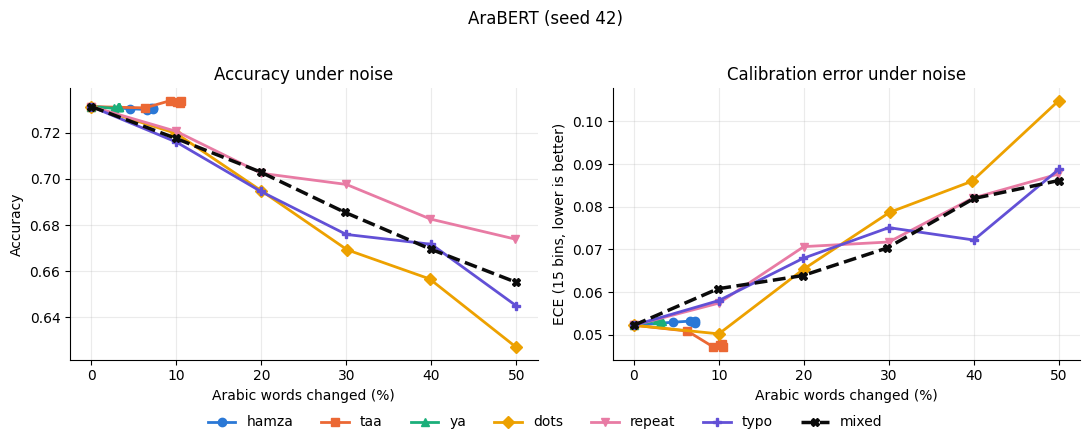

In [21]:
import matplotlib.pyplot as plt

# Fixed colour per noise type (colourblind-checked); markers give a second cue besides colour
COLORS  = {'hamza': '#2a78d6', 'taa': '#eb6834', 'ya': '#1baf7a', 'dots': '#eda100',
           'repeat': '#e87ba4', 'typo': '#6250d6', 'mixed': '#0b0b0b'}
MARKERS = {'hamza': 'o', 'taa': 's', 'ya': '^', 'dots': 'D', 'repeat': 'v', 'typo': 'P', 'mixed': 'X'}

def plot_vs_noise(res, metric, ylabel, ax):
    clean_val = res.loc[res['type'] == 'clean', metric].iloc[0]
    for t in CONFIG['noise_types']:
        d = res[res['type'] == t].sort_values('words_changed')
        x = np.r_[0, d['words_changed'] * 100]
        y = np.r_[clean_val, d[metric]]
        ax.plot(x, y, color=COLORS[t], marker=MARKERS[t], markersize=6,
                linewidth=2.5 if t == 'mixed' else 2, linestyle='--' if t == 'mixed' else '-', label=t)
    ax.set_xlabel('Arabic words changed (%)')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_vs_noise(res, 'accuracy', 'Accuracy', axes[0])
plot_vs_noise(res, 'ece_15', 'ECE (15 bins, lower is better)', axes[1])
axes[0].set_title('Accuracy under noise')
axes[1].set_title('Calibration error under noise')
handles, lbls = axes[0].get_legend_handles_labels()
fig.legend(handles, lbls, loc='lower center', ncol=7, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('AraBERT (seed 42)', y=1.02)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/noise_curves_AraBERT_s42.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.4 Reliability diagrams: clean text vs. heavy noise

A reliability diagram is a picture of calibration. Predictions are grouped by confidence (horizontal axis), and each bar shows how often that group was actually right (vertical axis).
- On a perfectly honest model, the bars reach exactly up to the dashed diagonal line.
- Bars **below** the line mean the model is **overconfident**: it is right less often than it claims.

**Result:** the bars are below the line on clean text, and they move further below as noise increases.

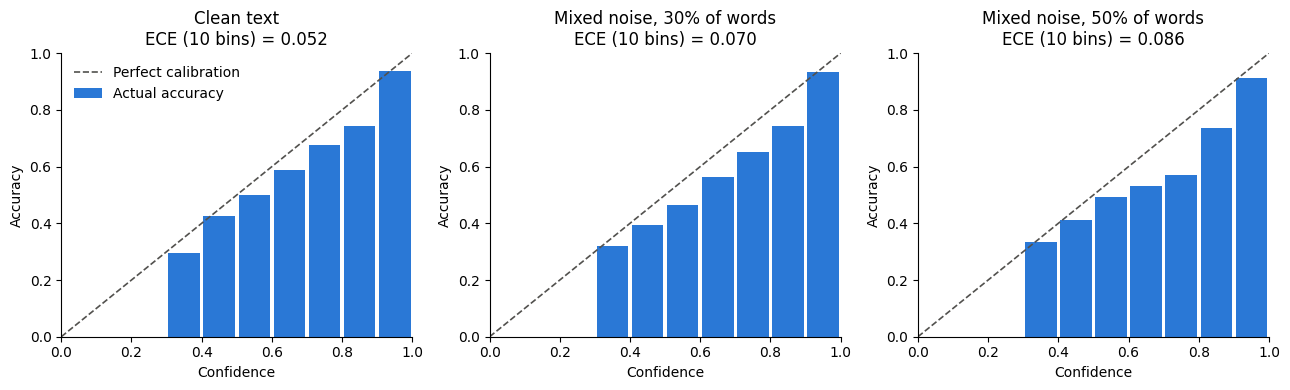

In [22]:
def reliability(ax, logits, labels, title, n_bins=10):
    probs = softmax(logits.astype(np.float64), axis=1)
    conf, correct = probs.max(1), probs.argmax(1) == labels
    edges = np.linspace(0, 1, n_bins + 1)
    centers = (edges[:-1] + edges[1:]) / 2
    accs = [correct[(conf > lo) & (conf <= hi)].mean() if ((conf > lo) & (conf <= hi)).any() else np.nan
            for lo, hi in zip(edges[:-1], edges[1:])]
    ax.bar(centers, accs, width=1 / n_bins - 0.01, color='#2a78d6', label='Actual accuracy')
    ax.plot([0, 1], [0, 1], '--', color='#52514e', linewidth=1.2, label='Perfect calibration')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Confidence'); ax.set_ylabel('Accuracy')
    ax.set_title(f'{title}\nECE (10 bins) = {ece_score(probs, labels, n_bins):.3f}')
    ax.spines[['top', 'right']].set_visible(False)

L = np.load(f'{LOGITS_DIR}/AraBERT_standard_s42.npz')
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
reliability(axes[0], L['test_clean'], L['test_labels'], 'Clean text')
reliability(axes[1], L['mixed_0.3'], L['test_labels'], 'Mixed noise, 30% of words')
reliability(axes[2], L['mixed_0.5'], L['test_labels'], 'Mixed noise, 50% of words')
axes[0].legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/reliability_AraBERT_s42.png', dpi=300, bbox_inches='tight')
plt.show()

---
## <font color="#1c5cab">7. Calibration methods</font>

Section 6 showed that the models are overconfident, especially on messy text. This section tests ways to make their confidence honest again:

| Method | How it works, simply | Needs retraining? |
|---|---|---|
| **TS** (temperature scaling) | Turns all confidences down by a fixed amount, learned on clean validation reviews | No |
| **TTS** (transferable TS) | Measures how messy the incoming reviews look, and turns confidence down more when they are messier | No |
| **MC dropout** | Asks the model the same question 10 times with small random changes, and averages the answers | No (but 10× slower to predict) |
| **Noise-augmented training** | Retrains the model on reviews that contain spelling mistakes | Yes |
| **Normalization** | Cleans up the spelling before the model reads it (tested as a simple defense) | No |

None of these methods change the model's structure; they change how its confidence is computed, or the data it learns from.

### 7.1 Temperature scaling and transferable TS

**Temperature scaling (TS):** the model's raw scores are divided by a number `T` before they become probabilities. `T > 1` makes the model less confident. The best `T` is found on the clean validation set.

**Transferable TS (TTS)** (Zhang et al., AAAI 2023): on messy text the model's answers become less certain overall (higher "entropy"). TTS measures how much more uncertain the model is on the new reviews than on the clean validation set, and raises `T` by the same proportion. It needs no clean copy of the new reviews, so it would also work in real use. It does need a **batch** of reviews to measure, not a single one.

In [23]:
from scipy.optimize import minimize_scalar

def fit_temperature(logits, labels):
    """Find T that minimizes NLL on the validation set."""
    logits = logits.astype(np.float64)
    loss = lambda logT: nll_score(softmax(logits / np.exp(logT), axis=1), labels)
    r = minimize_scalar(loss, bounds=(-2, 2), method='bounded')
    return float(np.exp(r.x))

def mean_entropy(logits):
    p = softmax(logits.astype(np.float64), axis=1)
    return float(np.mean(-np.sum(p * np.log(p + 1e-12), axis=1)))

def transferable_T(T_clean, val_logits, test_logits):
    """Zhang et al. (AAAI 2023): T_noisy = (1 + shift) * T_clean.
    Shift = relative rise in mean entropy vs. the clean validation set (no clean copy needed)."""
    h_val = mean_entropy(val_logits)
    shift = (mean_entropy(test_logits) - h_val) / h_val
    return T_clean * (1 + shift)

### 7.2 Evaluate all models with all three settings

This cell evaluates every trained model (all seeds) on every test set, three ways: no fix, TS and TTS. All results are saved to `results/all_results.csv`.

The table shows the temperature `T` learned for each model and seed. **All values are above 1**, which confirms that every model is overconfident even on clean text.

In [24]:
def evaluate_run_all(name):
    L = np.load(f'{LOGITS_DIR}/{name}.npz')
    labels = L['test_labels']
    T_c = fit_temperature(L['val'], L['val_labels'])
    model, variant, seed = name.split('_')[0], name.split('_')[1], int(name.split('_s')[-1])

    sets = [('test_clean', 'clean', 0.0)] + \
           [(f'{t}_{lv}', t, lv) for t in CONFIG['noise_types'] for lv in CONFIG['noise_levels']]
    rows = []
    for key, t, lv in sets:
        logits = L[key]
        wc = 0.0 if t == 'clean' else rates_df.loc[t, lv]
        T_t = transferable_T(T_c, L['val'], logits)
        for method, T in [('none', 1.0), ('TS', T_c), ('TTS', T_t)]:
            rows.append({'run': name, 'model': model, 'variant': variant, 'seed': seed,
                         'method': method, 'T': T, 'type': t, 'level': lv,
                         'words_changed': wc, **evaluate(logits, labels, T)})
    return pd.DataFrame(rows)

runs = sorted(os.path.basename(f)[:-4] for f in glob.glob(f'{LOGITS_DIR}/*.npz'))
print(f'{len(runs)} runs found:', runs)
all_res = pd.concat([evaluate_run_all(r) for r in runs], ignore_index=True)
all_res.to_csv(f'{RESULTS_DIR}/all_results.csv', index=False)

# Fitted temperatures on clean validation data
print('\nTemperature fitted on clean validation set (T > 1 = model was overconfident):')
display(all_res[(all_res['method'] == 'TS') & (all_res['type'] == 'clean')]
        .pivot_table(index=['variant', 'model'], columns='seed', values='T').round(2))

18 runs found: ['AraBERT_noiseaug_s42', 'AraBERT_noiseaug_s43', 'AraBERT_noiseaug_s44', 'AraBERT_standard_s42', 'AraBERT_standard_s43', 'AraBERT_standard_s44', 'CAMeLBERT_noiseaug_s42', 'CAMeLBERT_noiseaug_s43', 'CAMeLBERT_noiseaug_s44', 'CAMeLBERT_standard_s42', 'CAMeLBERT_standard_s43', 'CAMeLBERT_standard_s44', 'MARBERT_noiseaug_s42', 'MARBERT_noiseaug_s43', 'MARBERT_noiseaug_s44', 'MARBERT_standard_s42', 'MARBERT_standard_s43', 'MARBERT_standard_s44']

Temperature fitted on clean validation set (T > 1 = model was overconfident):


seed                  42    43    44
variant  model                      
noiseaug AraBERT    1.25  1.45  1.47
         CAMeLBERT  1.36  1.68  1.37
         MARBERT    1.04  1.35  1.36
standard AraBERT    1.27  1.50  1.51
         CAMeLBERT  1.70  1.18  1.32
         MARBERT    1.05  1.20  1.36

### 7.3 Summary tables

Calibration error (ECE) for each model and method, as the average ± the variation across the three seeds, on clean text and on two heavy-noise test sets.

**Result:** TS works on clean text but its error grows under noise (for AraBERT with 50% dot noise: 0.066). TTS stays low everywhere (0.026). None of these methods change accuracy.

In [25]:
def mean_std_table(df_, col):
    g = df_.groupby(['model', 'method'])[col].agg(['mean', 'std'])
    txt = g['mean'].map('{:.3f}'.format) + ' ± ' + g['std'].map('{:.3f}'.format)
    return txt.unstack('method')[['none', 'TS', 'TTS']]

std = all_res[all_res['variant'] == 'standard']
for title, sub in [('Clean test set', std[std['type'] == 'clean']),
                   ('Mixed noise, 50% of words', std[(std['type'] == 'mixed') & (std['level'] == 0.5)]),
                   ('Dots noise, 50% of words', std[(std['type'] == 'dots') & (std['level'] == 0.5)])]:
    print(f'\n{title}: ECE (15 bins)')
    display(mean_std_table(sub, 'ece_15'))
print('\nClean test set: accuracy (TS does not change accuracy)')
display(mean_std_table(std[std['type'] == 'clean'], 'accuracy'))


Clean test set: ECE (15 bins)


method,none,TS,TTS
model,,,
AraBERT,0.080 ± 0.025,0.022 ± 0.009,0.023 ± 0.010
CAMeLBERT,0.074 ± 0.044,0.023 ± 0.011,0.023 ± 0.012
MARBERT,0.055 ± 0.027,0.030 ± 0.008,0.031 ± 0.009



Mixed noise, 50% of words: ECE (15 bins)


method,none,TS,TTS
model,,,
AraBERT,0.112 ± 0.022,0.045 ± 0.002,0.025 ± 0.001
CAMeLBERT,0.119 ± 0.054,0.058 ± 0.019,0.040 ± 0.014
MARBERT,0.078 ± 0.040,0.046 ± 0.019,0.030 ± 0.014



Dots noise, 50% of words: ECE (15 bins)


method,none,TS,TTS
model,,,
AraBERT,0.132 ± 0.024,0.066 ± 0.006,0.026 ± 0.005
CAMeLBERT,0.148 ± 0.053,0.086 ± 0.018,0.053 ± 0.010
MARBERT,0.095 ± 0.051,0.064 ± 0.028,0.041 ± 0.019



Clean test set: accuracy (TS does not change accuracy)


method,none,TS,TTS
model,,,
AraBERT,0.730 ± 0.003,0.730 ± 0.003,0.730 ± 0.003
CAMeLBERT,0.714 ± 0.007,0.714 ± 0.007,0.714 ± 0.007
MARBERT,0.723 ± 0.006,0.723 ± 0.006,0.723 ± 0.006


### 7.4 Calibration error under mixed noise, per model and method

One chart per model. Each line is a method; the bars show the variation across the three seeds.

**Result:** without a fix (blue), the error rises with noise. TS (orange) starts low but rises. **TTS (green) stays low and flat** for all three models.

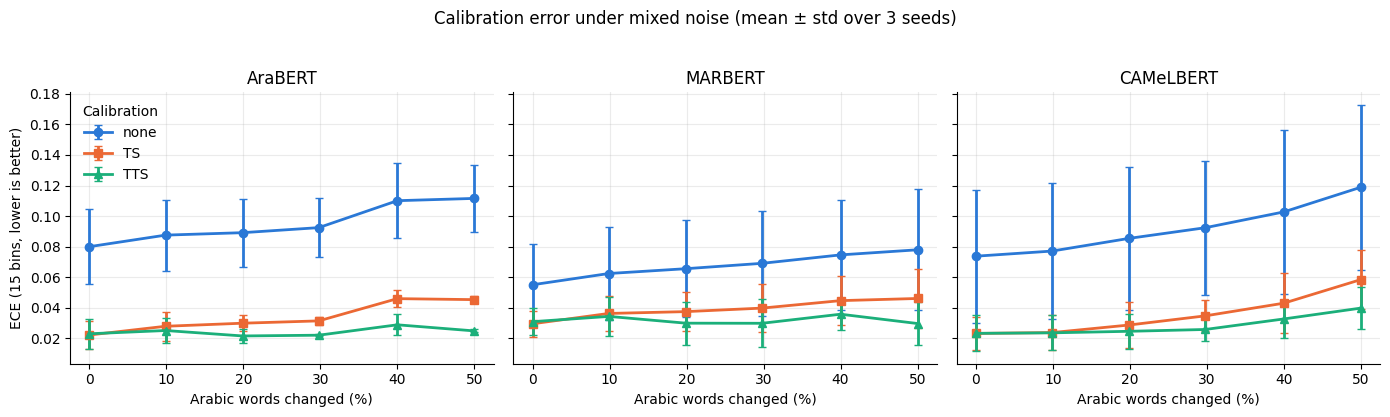

In [26]:
import matplotlib.pyplot as plt
METHOD_COLORS = {'none': '#2a78d6', 'TS': '#eb6834', 'TTS': '#1baf7a'}
METHOD_MARKERS = {'none': 'o', 'TS': 's', 'TTS': '^'}
models = list(CONFIG['models'])

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, m in zip(axes, models):
    d = std[(std['model'] == m) & (std['type'].isin(['clean', 'mixed']))]
    for method in ['none', 'TS', 'TTS']:
        g = d[d['method'] == method].groupby('words_changed')['ece_15'].agg(['mean', 'std']).reset_index()
        ax.errorbar(g['words_changed'] * 100, g['mean'], yerr=g['std'], color=METHOD_COLORS[method],
                    marker=METHOD_MARKERS[method], markersize=6, linewidth=2, capsize=3, label=method)
    ax.set_title(m)
    ax.set_xlabel('Arabic words changed (%)')
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('ECE (15 bins, lower is better)')
axes[0].legend(frameon=False, title='Calibration')
fig.suptitle('Calibration error under mixed noise (mean ± std over 3 seeds)', y=1.03)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/ece_methods_mixed.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.5 MC dropout functions

During training, **dropout** randomly switches off 10% of the model's internal connections, which helps it avoid memorizing the training data. Normally dropout is switched off when the model makes predictions.

**MC dropout** keeps it switched on and runs each review **10 times**. Each run switches off different connections, so the answers vary a little. The average of the 10 answers is used as the prediction. If the 10 answers disagree, the model is unsure.

To save GPU time, it is run on 8 test sets: clean text, mixed noise at all five levels, and dots and typo noise at 50%. It reuses the trained models; no retraining is needed.

In [27]:
MC_DIR = f'{RESULTS_DIR}/mcdropout'
os.makedirs(MC_DIR, exist_ok=True)
CONFIG['mc'] = {'passes': 10,
                'sets': ['test_clean'] + [f'mixed_{lv}' for lv in CONFIG['noise_levels']]
                        + ['dots_0.5', 'typo_0.5']}

def load_set(key):
    return test_df if key == 'test_clean' else pd.read_csv(f'{NOISY_DIR}/{key}.csv')

@torch.no_grad()
def mc_dropout_probs(model, tok, texts, passes, batch_size=128):
    """Average softmax probabilities over several passes with dropout switched ON."""
    enc = tok(list(texts), truncation=True, max_length=CONFIG['max_len'])
    order = np.argsort([len(x) for x in enc['input_ids']])   # similar lengths together = faster
    probs = np.zeros((len(texts), 3))
    for s in range(0, len(order), batch_size):
        idx = order[s:s + batch_size]
        batch = tok.pad({'input_ids': [enc['input_ids'][i] for i in idx],
                         'attention_mask': [enc['attention_mask'][i] for i in idx]},
                        return_tensors='pt').to('cuda')
        p = 0
        for _ in range(passes):
            p = p + torch.softmax(model(**batch).logits.float(), dim=-1)
        probs[idx] = (p / passes).cpu().numpy()
    return probs

def run_mc(name):
    out_path = f'{MC_DIR}/{name}.npz'
    if os.path.exists(out_path):
        print(f'{name}: MC dropout already done, skipping.')
        return
    set_seed(CONFIG['seed'])
    tok = AutoTokenizer.from_pretrained(f'{MODELS_DIR}/{name}')
    model = AutoModelForSequenceClassification.from_pretrained(f'{MODELS_DIR}/{name}').half().to('cuda')
    model.train()   # train mode = dropout ON (BERT has no other layers that change in train mode)

    t0 = time.time()
    out = {key: mc_dropout_probs(model, tok, load_set(key)['text'], CONFIG['mc']['passes'])
           for key in CONFIG['mc']['sets']}
    np.savez_compressed(out_path, **out)
    del model
    torch.cuda.empty_cache()
    print(f'{name}: MC dropout done in {(time.time() - t0) / 60:.1f} min')

### 7.6 Test on one model first (to measure the time)

Runs MC dropout on one model to check that it works and how long it takes. **Result:** about 7 minutes per model.

In [28]:
run_mc('AraBERT_standard_s42')

AraBERT_standard_s42: MC dropout already done, skipping.


### 7.7 Run MC dropout for all standard models

Runs MC dropout for the remaining standard models (about 1 hour). Finished models are skipped.

In [30]:
for name in [r for r in runs if '_standard_' in r]:
    run_mc(name)   # MC dropout for standard models only; finished ones are skipped

AraBERT_standard_s42: MC dropout already done, skipping.
AraBERT_standard_s43: MC dropout already done, skipping.
AraBERT_standard_s44: MC dropout already done, skipping.
CAMeLBERT_standard_s42: MC dropout already done, skipping.
CAMeLBERT_standard_s43: MC dropout already done, skipping.
CAMeLBERT_standard_s44: MC dropout already done, skipping.
MARBERT_standard_s42: MC dropout already done, skipping.
MARBERT_standard_s43: MC dropout already done, skipping.
MARBERT_standard_s44: MC dropout already done, skipping.


### 7.8 Compare all four methods

Calibration error for no fix, MC dropout, TS and TTS, side by side.

**Result:** the ranking is the same everywhere: **TTS** (best) > TS > MC dropout > no fix. MC dropout helps only a little (about 25–30% lower error than no fix) while costing 10 times more computation.

In [31]:
import matplotlib.pyplot as plt

mc_rows = []
for name in runs:
    if not os.path.exists(f'{MC_DIR}/{name}.npz'):
        continue
    M = np.load(f'{MC_DIR}/{name}.npz')
    labels = np.load(f'{LOGITS_DIR}/{name}.npz')['test_labels']
    model, variant, seed = name.split('_')[0], name.split('_')[1], int(name.split('_s')[-1])
    for key in M.files:
        t, lv = ('clean', 0.0) if key == 'test_clean' else (key.rsplit('_', 1)[0], float(key.rsplit('_', 1)[1]))
        wc = 0.0 if t == 'clean' else rates_df.loc[t, lv]
        # log of probabilities works as logits: softmax(log p) = p
        mc_rows.append({'run': name, 'model': model, 'variant': variant, 'seed': seed,
                        'method': 'MC', 'T': 1.0, 'type': t, 'level': lv, 'words_changed': wc,
                        **evaluate(np.log(M[key] + 1e-12), labels)})

all_res = pd.concat([all_res[all_res['method'] != 'MC'], pd.DataFrame(mc_rows)], ignore_index=True)
all_res.to_csv(f'{RESULTS_DIR}/all_results.csv', index=False)

def table4(df_, col='ece_15', methods=('none', 'TS', 'TTS', 'MC')):
    g = df_.groupby(['model', 'method'])[col].agg(['mean', 'std'])
    txt = g['mean'].map('{:.3f}'.format) + ' ± ' + g['std'].map('{:.3f}'.format)
    return txt.unstack('method')[[m for m in methods if m in txt.index.get_level_values('method')]]

std = all_res[all_res['variant'] == 'standard']
for title, t, lv in [('Clean', 'clean', 0.0), ('Mixed 50%', 'mixed', 0.5),
                     ('Dots 50%', 'dots', 0.5), ('Typo 50%', 'typo', 0.5)]:
    print(f'\n{title}: ECE (15 bins)')
    display(table4(std[(std['type'] == t) & (std['level'] == lv)]))
print('\nClean: accuracy (MC dropout can change accuracy slightly)')
display(table4(std[std['type'] == 'clean'], 'accuracy'))


Clean: ECE (15 bins)


method,none,TS,TTS,MC
model,,,,
AraBERT,0.080 ± 0.025,0.022 ± 0.009,0.023 ± 0.010,0.059 ± 0.023
CAMeLBERT,0.074 ± 0.044,0.023 ± 0.011,0.023 ± 0.012,0.051 ± 0.039
MARBERT,0.055 ± 0.027,0.030 ± 0.008,0.031 ± 0.009,0.033 ± 0.018



Mixed 50%: ECE (15 bins)


method,none,TS,TTS,MC
model,,,,
AraBERT,0.112 ± 0.022,0.045 ± 0.002,0.025 ± 0.001,0.079 ± 0.017
CAMeLBERT,0.119 ± 0.054,0.058 ± 0.019,0.040 ± 0.014,0.088 ± 0.047
MARBERT,0.078 ± 0.040,0.046 ± 0.019,0.030 ± 0.014,0.039 ± 0.033



Dots 50%: ECE (15 bins)


method,none,TS,TTS,MC
model,,,,
AraBERT,0.132 ± 0.024,0.066 ± 0.006,0.026 ± 0.005,0.098 ± 0.016
CAMeLBERT,0.148 ± 0.053,0.086 ± 0.018,0.053 ± 0.010,0.122 ± 0.047
MARBERT,0.095 ± 0.051,0.064 ± 0.028,0.041 ± 0.019,0.057 ± 0.036



Typo 50%: ECE (15 bins)


method,none,TS,TTS,MC
model,,,,
AraBERT,0.116 ± 0.024,0.051 ± 0.004,0.023 ± 0.001,0.084 ± 0.017
CAMeLBERT,0.118 ± 0.058,0.056 ± 0.024,0.031 ± 0.008,0.093 ± 0.049
MARBERT,0.080 ± 0.043,0.049 ± 0.023,0.031 ± 0.009,0.040 ± 0.031



Clean: accuracy (MC dropout can change accuracy slightly)


method,none,TS,TTS,MC
model,,,,
AraBERT,0.730 ± 0.003,0.730 ± 0.003,0.730 ± 0.003,0.729 ± 0.004
CAMeLBERT,0.714 ± 0.007,0.714 ± 0.007,0.714 ± 0.007,0.715 ± 0.006
MARBERT,0.723 ± 0.006,0.723 ± 0.006,0.723 ± 0.006,0.722 ± 0.005


### 7.9 Create the noisy training set

For noise-augmented training, the models must see spelling mistakes while they learn. This cell takes the 25,200 training reviews and adds mixed noise (at a random level between 10% and 50%) to **half** of them; the other half stay clean. The training set keeps the same size, so training takes the same time.

The noise here uses different random seeds from the test noise, so the models never see the exact noisy test reviews. The validation set stays **clean**, so the best epoch and the temperature are chosen the same way as for the standard models. The new training set is saved as `train_noiseaug.csv`.

In [32]:
AUG_PATH = f'{SPLIT_DIR}/train_noiseaug.csv'

if os.path.exists(AUG_PATH):
    train_aug = pd.read_csv(AUG_PATH)
    print('Loaded noise-augmented training set from Drive.')
else:
    aug_rng = np.random.default_rng([CONFIG['seed'], 999])
    noisy_mask = aug_rng.random(len(train_df)) < 0.5            # half the reviews get noise
    texts = []
    for (rid, text), noisy in zip(zip(train_df['id'], train_df['text']), noisy_mask):
        if noisy:
            rng = np.random.default_rng([CONFIG['seed'], 999, int(rid)])   # different seeds from the test noise
            level = CONFIG['noise_levels'][rng.integers(len(CONFIG['noise_levels']))]
            text, _ = add_noise(text, 'mixed', level, rng)
        texts.append(text)
    train_aug = train_df.assign(text=texts, noisy=noisy_mask)
    train_aug.to_csv(AUG_PATH, index=False)
    print('Created and saved noise-augmented training set.')

print(f"{train_aug['noisy'].sum()} of {len(train_aug)} training reviews have noise")
print('\nExample:')
ex = train_aug[train_aug['noisy']].iloc[0]
print('CLEAN:', train_df.set_index('id').loc[ex['id'], 'text'][:150])
print('NOISY:', ex['text'][:150])

Loaded noise-augmented training set from Drive.
12683 of 25200 training reviews have noise

Example:
CLEAN: هو الكتاب بيبدأ بإن البطل بيسافر عشان عنده اسئلة كتير محتاج يتجاوب عليها. وبيخلص والاسئلة دي يعتبر متجاوبتش برضه : . وفي نص الكتاب كل شخصية بتقعد تحكي
NOISY: هوووو الكتاب بيبدأ بإن البطا بيسافر عشان عنده اسئللللة تكير محتااااج يتجاوت غليها. وبيييخلص الاسئلة دي يعتبر متجاوبتش برضه : . وفي نصصص الكتاث كللل شخ


### 7.10 Train the 9 noise-augmented models

Trains each model with each seed on the noisy training set (3 × 3 = 9 runs, about 4.5 hours). The models are saved as `<Model>_noiseaug_s<seed>`. Finished runs are skipped after a disconnect.

In [33]:
for seed in CONFIG['seeds']:
    for model_key in CONFIG['models']:
        train_model(model_key, seed, train_data=train_aug, variant='noiseaug')

AraBERT_noiseaug_s42: already trained, skipping.
MARBERT_noiseaug_s42: already trained, skipping.
CAMeLBERT_noiseaug_s42: already trained, skipping.
AraBERT_noiseaug_s43: already trained, skipping.
MARBERT_noiseaug_s43: already trained, skipping.
CAMeLBERT_noiseaug_s43: already trained, skipping.
AraBERT_noiseaug_s44: already trained, skipping.
MARBERT_noiseaug_s44: already trained, skipping.
CAMeLBERT_noiseaug_s44: already trained, skipping.


### 7.11 Standard vs. noise-augmented training

Compares the models trained on clean reviews ("standard") with those trained on noisy reviews ("noiseaug").

**Result:**
- **Accuracy on messy text improves by about 4 points** for every model (e.g. AraBERT with 50% mixed noise: 65.4% → 69.3%), with almost no loss on clean text.
- Confidence becomes only partly more honest; a calibration method is still needed.
- **Noise-augmented training + TTS** gives both: better accuracy and honest confidence.


Clean: ECE (15 bins)


method                       none             TS            TTS
model     variant                                              
AraBERT   noiseaug  0.079 ± 0.022  0.028 ± 0.010  0.029 ± 0.010
          standard  0.080 ± 0.025  0.022 ± 0.009  0.023 ± 0.010
CAMeLBERT noiseaug  0.086 ± 0.027  0.024 ± 0.007  0.024 ± 0.007
          standard  0.074 ± 0.044  0.023 ± 0.011  0.023 ± 0.012
MARBERT   noiseaug  0.065 ± 0.035  0.034 ± 0.012  0.036 ± 0.013
          standard  0.055 ± 0.027  0.030 ± 0.008  0.031 ± 0.009


Mixed 50%: ECE (15 bins)


method                       none             TS            TTS
model     variant                                              
AraBERT   noiseaug  0.087 ± 0.027  0.031 ± 0.011  0.025 ± 0.005
          standard  0.112 ± 0.022  0.045 ± 0.002  0.025 ± 0.001
CAMeLBERT noiseaug  0.101 ± 0.031  0.035 ± 0.010  0.027 ± 0.010
          standard  0.119 ± 0.054  0.058 ± 0.019  0.040 ± 0.014
MARBERT   noiseaug  0.076 ± 0.049  0.041 ± 0.021  0.035 ± 0.017
          standard  0.078 ± 0.040  0.046 ± 0.019  0.030 ± 0.014


Dots 50%: ECE (15 bins)


method                       none             TS            TTS
model     variant                                              
AraBERT   noiseaug  0.085 ± 0.024  0.030 ± 0.008  0.027 ± 0.006
          standard  0.132 ± 0.024  0.066 ± 0.006  0.026 ± 0.005
CAMeLBERT noiseaug  0.106 ± 0.040  0.042 ± 0.017  0.035 ± 0.016
          standard  0.148 ± 0.053  0.086 ± 0.018  0.053 ± 0.010
MARBERT   noiseaug  0.086 ± 0.052  0.053 ± 0.023  0.046 ± 0.017
          standard  0.095 ± 0.051  0.064 ± 0.028  0.041 ± 0.019

... (2 outputs left out)


Clean: accuracy


method                       none
model     variant                
AraBERT   noiseaug  0.725 ± 0.004
          standard  0.730 ± 0.003
CAMeLBERT noiseaug  0.712 ± 0.002
          standard  0.714 ± 0.007
MARBERT   noiseaug  0.724 ± 0.002
          standard  0.723 ± 0.006


Mixed 50%: accuracy


method                       none
model     variant                
AraBERT   noiseaug  0.693 ± 0.003
          standard  0.654 ± 0.003
CAMeLBERT noiseaug  0.679 ± 0.005
          standard  0.635 ± 0.002
MARBERT   noiseaug  0.687 ± 0.002
          standard  0.653 ± 0.004

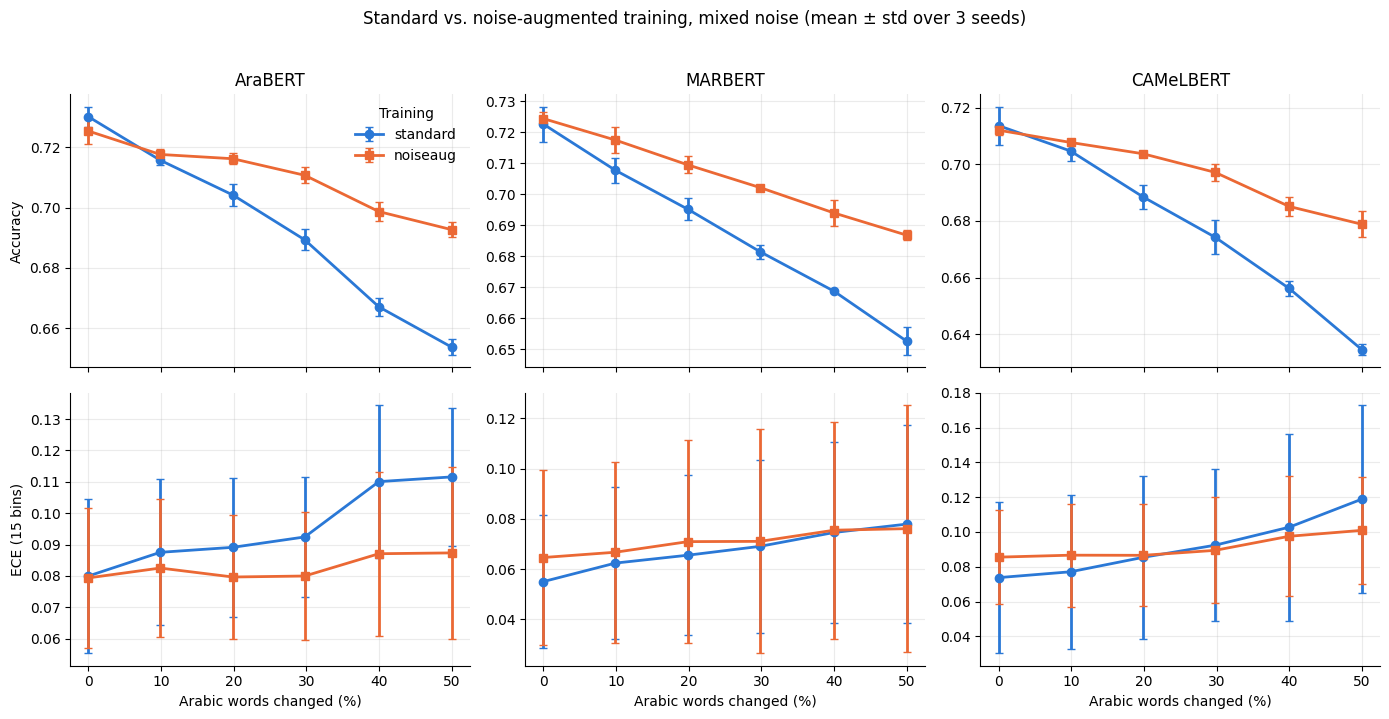

In [34]:
import matplotlib.pyplot as plt

def variant_table(df_, col='ece_15'):
    g = df_.groupby(['model', 'variant', 'method'])[col].agg(['mean', 'std'])
    txt = g['mean'].map('{:.3f}'.format) + ' ± ' + g['std'].map('{:.3f}'.format)
    return txt.unstack('method')[['none', 'TS', 'TTS']]

cmp_res = all_res[all_res['method'].isin(['none', 'TS', 'TTS'])]
for title, t, lv in [('Clean', 'clean', 0.0), ('Mixed 50%', 'mixed', 0.5),
                     ('Dots 50%', 'dots', 0.5), ('Typo 50%', 'typo', 0.5)]:
    print(f'\n{title}: ECE (15 bins)')
    display(variant_table(cmp_res[(cmp_res['type'] == t) & (cmp_res['level'] == lv)]))

for title, t, lv in [('Clean', 'clean', 0.0), ('Mixed 50%', 'mixed', 0.5)]:
    print(f'\n{title}: accuracy')
    display(variant_table(cmp_res[(cmp_res['type'] == t) & (cmp_res['level'] == lv)], 'accuracy')[['none']])

# Figure: accuracy and ECE (no fix) under mixed noise, standard vs noise-augmented
VAR_COLORS = {'standard': '#2a78d6', 'noiseaug': '#eb6834'}
VAR_MARKERS = {'standard': 'o', 'noiseaug': 's'}
d0 = cmp_res[(cmp_res['method'] == 'none') & (cmp_res['type'].isin(['clean', 'mixed']))]
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for j, m in enumerate(CONFIG['models']):
    for i, (metric, ylabel) in enumerate([('accuracy', 'Accuracy'), ('ece_15', 'ECE (15 bins)')]):
        ax = axes[i, j]
        for v in ['standard', 'noiseaug']:
            g = d0[(d0['model'] == m) & (d0['variant'] == v)] \
                  .groupby('words_changed')[metric].agg(['mean', 'std']).reset_index()
            ax.errorbar(g['words_changed'] * 100, g['mean'], yerr=g['std'], color=VAR_COLORS[v],
                        marker=VAR_MARKERS[v], linewidth=2, capsize=3, label=v)
        ax.grid(alpha=0.25)
        ax.spines[['top', 'right']].set_visible(False)
        if i == 0: ax.set_title(m)
        if j == 0: ax.set_ylabel(ylabel)
        if i == 1: ax.set_xlabel('Arabic words changed (%)')
axes[0, 0].legend(frameon=False, title='Training')
fig.suptitle('Standard vs. noise-augmented training, mixed noise (mean ± std over 3 seeds)', y=1.02)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/noiseaug_vs_standard.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.12 Predict on normalized text

Tests the simple defense from Section 4.4: the text is normalized before the (standard) models read it. Predictions are made on normalized versions of the validation set, the clean test set, and each noise type at 50%. About 10 minutes.

In [40]:
NORM_DIR = f'{RESULTS_DIR}/normalized'
os.makedirs(NORM_DIR, exist_ok=True)
NORM_SETS = ['val', 'test_clean'] + [f'{t}_0.5' for t in CONFIG['noise_types']]

@torch.no_grad()
def predict_logits(model, tok, texts, batch_size=128):
    enc = tok(list(texts), truncation=True, max_length=CONFIG['max_len'])
    order = np.argsort([len(x) for x in enc['input_ids']])
    out = np.zeros((len(texts), 3))
    for s in range(0, len(order), batch_size):
        idx = order[s:s + batch_size]
        batch = tok.pad({'input_ids': [enc['input_ids'][i] for i in idx],
                         'attention_mask': [enc['attention_mask'][i] for i in idx]},
                        return_tensors='pt').to('cuda')
        out[idx] = model(**batch).logits.float().cpu().numpy()
    return out

def run_norm(name):
    path = f'{NORM_DIR}/{name}.npz'
    if os.path.exists(path):
        print(f'{name}: normalization already done, skipping.')
        return
    tok = AutoTokenizer.from_pretrained(f'{MODELS_DIR}/{name}')
    model = AutoModelForSequenceClassification.from_pretrained(f'{MODELS_DIR}/{name}').half().to('cuda').eval()
    t0 = time.time()
    out = {}
    for key in NORM_SETS:
        df_ = val_df if key == 'val' else load_set(key)
        out[key] = predict_logits(model, tok, df_['text'].map(normalize_ar))
    np.savez_compressed(path, **out)
    del model
    torch.cuda.empty_cache()
    print(f'{name}: done in {(time.time() - t0) / 60:.1f} min')

for name in [r for r in runs if '_standard_' in r]:
    run_norm(name)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

AraBERT_standard_s42: done in 1.2 min


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

AraBERT_standard_s43: done in 1.0 min


Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

AraBERT_standard_s44: done in 0.9 min


... (8 outputs left out)

Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

MARBERT_standard_s43: done in 0.9 min


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

MARBERT_standard_s44: done in 0.9 min


### 7.13 Does normalization help?

Compares accuracy and calibration error on raw and normalized text, averaged over the 9 standard models.

**Result:** normalization fully fixes stretched letters (accuracy 65.8% → 71.8%) but does **nothing** for dot confusion or keyboard typos, which are the most damaging mistakes. TTS fixes the calibration for all types, and **normalization + TTS** is the best combination.

In [41]:
rows = []
for name in [r for r in runs if '_standard_' in r]:
    L = np.load(f'{LOGITS_DIR}/{name}.npz')
    N = np.load(f'{NORM_DIR}/{name}.npz')
    labels = L['test_labels']
    T_raw  = fit_temperature(L['val'], L['val_labels'])
    T_norm = fit_temperature(N['val'], L['val_labels'])
    for key in NORM_SETS[1:]:
        t = 'clean' if key == 'test_clean' else key.rsplit('_', 1)[0]
        for setup, logits, val_logits, T_c in [('raw', L[key], L['val'], T_raw),
                                                ('normalized', N[key], N['val'], T_norm)]:
            for method, T in [('none', 1.0), ('TTS', transferable_T(T_c, val_logits, logits))]:
                r = evaluate(logits, labels, T)
                rows.append({'run': name, 'type': t, 'setup': setup, 'method': method,
                             'accuracy': r['accuracy'], 'ece_15': r['ece_15']})

norm_res = pd.DataFrame(rows)
norm_res.to_csv(f'{RESULTS_DIR}/normalization_results.csv', index=False)

order = ['clean'] + CONFIG['noise_types']
acc = norm_res[norm_res['method'] == 'none'].pivot_table(index='type', columns='setup', values='accuracy').loc[order]
ece = norm_res.pivot_table(index='type', columns=['setup', 'method'], values='ece_15').loc[order]

print('Accuracy (average of 9 standard models; noise at 50%):')
display(acc[['raw', 'normalized']].round(3))
print('\nECE (15 bins):')
display(ece[[('raw', 'none'), ('normalized', 'none'), ('raw', 'TTS'), ('normalized', 'TTS')]].round(3))

Accuracy (average of 9 standard models; noise at 50%):


setup,raw,normalized
type,,
clean,0.722,0.719
hamza,0.722,0.719
taa,0.720,0.719
ya,0.721,0.719
dots,0.606,0.606
repeat,0.658,0.718
typo,0.625,0.621
mixed,0.647,0.667



ECE (15 bins):


setup,raw,normalized,raw,normalized
method,none,none,TTS,TTS
type,,,,
clean,0.070,0.070,0.026,0.026
hamza,0.070,0.070,0.026,0.026
taa,0.069,0.070,0.024,0.026
ya,0.071,0.070,0.027,0.026
dots,0.125,0.119,0.040,0.036
repeat,0.116,0.069,0.054,0.026
typo,0.105,0.103,0.028,0.027
mixed,0.103,0.086,0.031,0.025


---
## <font color="#1c5cab">8. Selective prediction</font>

In real use, a model doesn't have to answer every review. It can answer only when it is confident enough and send the rest to a person. This is called **selective prediction**. It is only useful if the model's confidence is honest, which is why calibration matters in practice.

**What we measure:**

1. **Risk–coverage:** if the model answers only the X% of reviews it is most sure about, how many of those answers are wrong? ("Coverage" is the share it answers; "risk" is its error rate on them.)
2. **The deployment test (the most important):** a company chooses a confidence threshold on **clean** data, aiming for "at most 10% wrong among the reviews the model answers". Then messy reviews arrive. **Does the error stay at 10%, or does it quietly grow?** This is where honest confidence should make a difference.

### 8.1 Functions

- `risk_coverage` sorts reviews from most to least confident and computes the error rate as more reviews are answered.
- `pick_threshold` finds the confidence threshold that keeps the error at the target (10%) on the clean validation set.
- `get_probs` returns the model's probabilities with no fix, TS or TTS.

In [35]:
import matplotlib.pyplot as plt
from scipy.special import softmax

def get_probs(L, key, method, T_c):
    """Probabilities for one test set with a given calibration method."""
    if method == 'none':
        T = 1.0
    elif method == 'TS':
        T = T_c
    else:  # TTS
        T = transferable_T(T_c, L['val'], L[key])
    return softmax(L[key].astype(np.float64) / T, axis=1)

def risk_coverage(probs, labels):
    """Answer the most confident reviews first; risk = error rate among the answered ones."""
    conf, err = probs.max(1), probs.argmax(1) != labels
    order = np.argsort(-conf)
    n = len(err)
    coverage = np.arange(1, n + 1) / n
    risk = np.cumsum(err[order]) / np.arange(1, n + 1)
    return coverage, risk, conf[order]

def risk_at_coverage(probs, labels, cov):
    _, risk, _ = risk_coverage(probs, labels)
    return risk[int(np.ceil(cov * len(risk))) - 1]

def pick_threshold(probs, labels, target_risk):
    """Lowest confidence threshold that keeps the error among accepted reviews <= target (on validation)."""
    _, risk, conf_sorted = risk_coverage(probs, labels)
    ok = np.where(risk <= target_risk)[0]
    return conf_sorted[ok.max()] if len(ok) else 1.0

CONFIG['selective'] = {'target_risk': 0.10, 'coverages': [0.9, 0.8]}

### 8.2 Compute everything for all 18 models

Applies the risk–coverage analysis and the deployment test to all 18 trained models (9 standard and 9 noise-augmented) and the three settings (no fix, TS, TTS). Results are saved to `results/selective_results.csv`.

In [36]:
sel_sets = [('test_clean', 'clean', 0.0)] + \
           [(f'mixed_{lv}', 'mixed', lv) for lv in CONFIG['noise_levels']] + \
           [('dots_0.5', 'dots', 0.5), ('typo_0.5', 'typo', 0.5)]
target = CONFIG['selective']['target_risk']

rows = []
for name in runs:
    L = np.load(f'{LOGITS_DIR}/{name}.npz')
    labels, val_labels = L['test_labels'], L['val_labels']
    T_c = fit_temperature(L['val'], val_labels)
    model, variant, seed = name.split('_')[0], name.split('_')[1], int(name.split('_s')[-1])
    for method in ['none', 'TS', 'TTS']:
        # Threshold chosen once on CLEAN validation data (TTS = TS on validation, since shift = 0)
        val_probs = softmax(L['val'].astype(np.float64) / (1.0 if method == 'none' else T_c), axis=1)
        tau = pick_threshold(val_probs, val_labels, target)
        for key, t, lv in sel_sets:
            p = get_probs(L, key, method, T_c)
            _, risk, _ = risk_coverage(p, labels)
            accept = p.max(1) >= tau
            err = p.argmax(1) != labels
            rows.append({'model': model, 'variant': variant, 'seed': seed, 'method': method,
                         'type': t, 'level': lv,
                         'words_changed': 0.0 if t == 'clean' else rates_df.loc[t, lv],
                         'aurc': risk.mean(),
                         'risk_full': err.mean(),
                         'risk_cov90': risk_at_coverage(p, labels, 0.9),
                         'risk_cov80': risk_at_coverage(p, labels, 0.8),
                         'threshold': tau,
                         'coverage_at_tau': accept.mean(),
                         'risk_at_tau': err[accept].mean() if accept.any() else np.nan})

sel = pd.DataFrame(rows)
sel.to_csv(f'{RESULTS_DIR}/selective_results.csv', index=False)
print(len(sel), 'rows saved')

432 rows saved


### 8.3 How much does abstaining help?

The error rate when the model answers all reviews, or only its 90% or 80% most confident ones.

**Result:** on clean text, AraBERT is wrong on 27.0% of all reviews, but only 20.8% of its most confident 80%. Sending the least confident 20% to a person cuts errors by about a quarter.

In [37]:
def ms(df_, col):
    g = df_.groupby(['model', 'method'])[col].agg(['mean', 'std'])
    return (g['mean'].map('{:.3f}'.format) + ' ± ' + g['std'].map('{:.3f}'.format)).unstack('method')[['none', 'TS', 'TTS']]

s = sel[sel['variant'] == 'standard']
for title, t, lv in [('Clean', 'clean', 0.0), ('Mixed 50%', 'mixed', 0.5), ('Dots 50%', 'dots', 0.5)]:
    d = s[(s['type'] == t) & (s['level'] == lv)]
    print(f'\n{title}: error rate when the model answers only its most confident reviews (method: none)')
    display(d[d['method'] == 'none'].groupby('model')[['risk_full', 'risk_cov90', 'risk_cov80']].mean()
            .round(3).set_axis(['answer 100%', 'answer 90%', 'answer 80%'], axis=1))


Clean: error rate when the model answers only its most confident reviews (method: none)


,answer 100%,answer 90%,answer 80%
model,,,
AraBERT,0.270,0.239,0.208
CAMeLBERT,0.286,0.256,0.226
MARBERT,0.277,0.246,0.216



Mixed 50%: error rate when the model answers only its most confident reviews (method: none)


,answer 100%,answer 90%,answer 80%
model,,,
AraBERT,0.346,0.320,0.295
CAMeLBERT,0.365,0.341,0.313
MARBERT,0.347,0.319,0.291



Dots 50%: error rate when the model answers only its most confident reviews (method: none)


,answer 100%,answer 90%,answer 80%
model,,,
AraBERT,0.380,0.355,0.328
CAMeLBERT,0.414,0.391,0.368
MARBERT,0.388,0.361,0.333


### 8.4 The deployment test (threshold set on clean data, used on messy data)

For each model and method: the actual error among the reviews the model accepts, and the share it accepts (the rest go to a person). The chart shows how both change as noise increases; the dashed line is the 10% target.

**Result:** without a fix (and with TS, which gives the same result here), the promised 10% error quietly grows to 15–22% on messy reviews. With **TTS**, the model becomes less confident on messy reviews, sends more of them to a person, and the error stays closer to the target. **TTS cuts the extra error roughly in half**, though it does not remove it completely.

Target: at most 10% errors among accepted reviews. Threshold set on clean validation data.

Clean: actual error among accepted reviews


method,none,TS,TTS
model,,,
AraBERT,0.104 ± 0.000,0.103 ± 0.002,0.104 ± 0.002
CAMeLBERT,0.099 ± 0.004,0.099 ± 0.005,0.100 ± 0.005
MARBERT,0.107 ± 0.007,0.106 ± 0.007,0.108 ± 0.008


Clean: share of reviews accepted (the rest go to a human)


method,none,TS,TTS
model,,,
AraBERT,0.516 ± 0.004,0.515 ± 0.007,0.516 ± 0.008
CAMeLBERT,0.478 ± 0.014,0.479 ± 0.015,0.482 ± 0.018
MARBERT,0.505 ± 0.023,0.505 ± 0.020,0.509 ± 0.023


Mixed 50%: actual error among accepted reviews


method,none,TS,TTS
model,,,
AraBERT,0.151 ± 0.004,0.150 ± 0.003,0.124 ± 0.002
CAMeLBERT,0.167 ± 0.022,0.166 ± 0.024,0.143 ± 0.026
MARBERT,0.143 ± 0.015,0.143 ± 0.016,0.122 ± 0.015


... (2 outputs left out)

Dots 50%: actual error among accepted reviews


method,none,TS,TTS
model,,,
AraBERT,0.195 ± 0.005,0.193 ± 0.003,0.153 ± 0.007
CAMeLBERT,0.216 ± 0.021,0.218 ± 0.023,0.178 ± 0.042
MARBERT,0.163 ± 0.026,0.162 ± 0.026,0.127 ± 0.018


Dots 50%: share of reviews accepted (the rest go to a human)


method,none,TS,TTS
model,,,
AraBERT,0.398 ± 0.023,0.399 ± 0.025,0.311 ± 0.043
CAMeLBERT,0.370 ± 0.029,0.370 ± 0.031,0.299 ± 0.036
MARBERT,0.352 ± 0.051,0.351 ± 0.050,0.284 ± 0.043


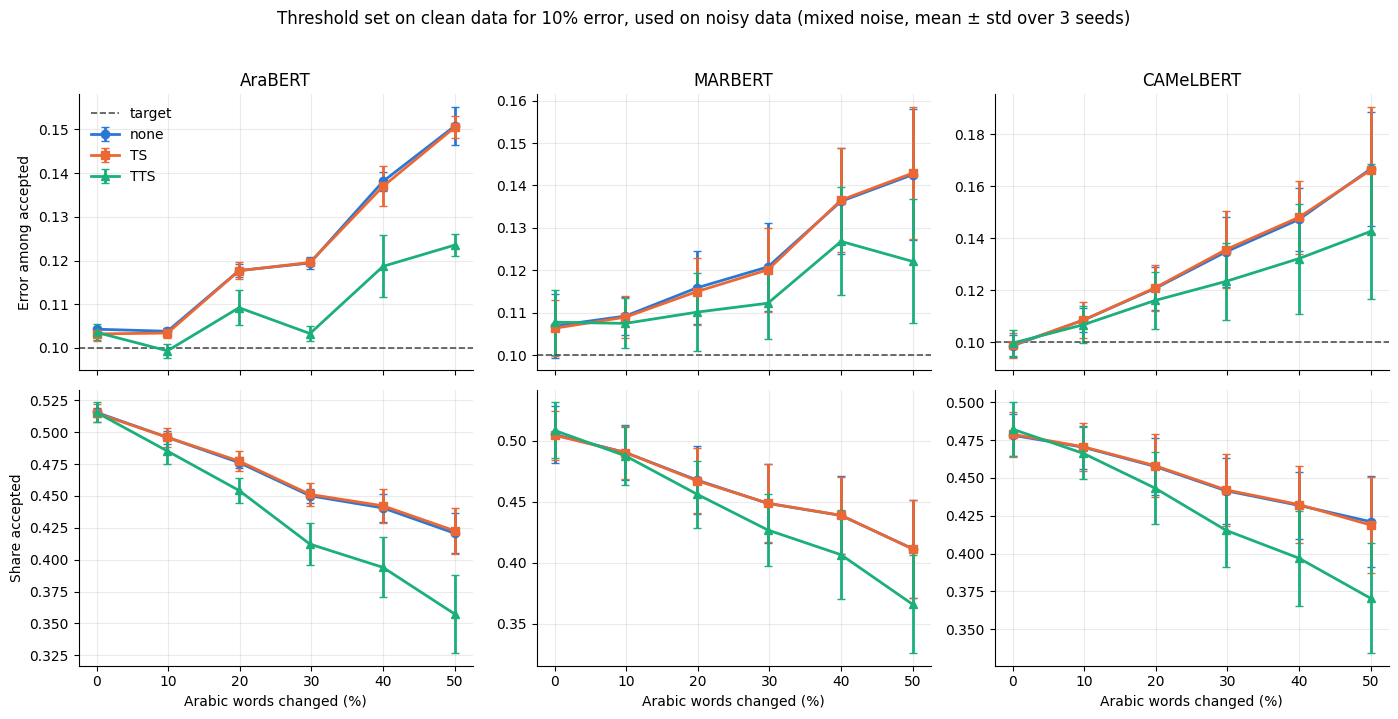

In [38]:
print(f'Target: at most {target:.0%} errors among accepted reviews. Threshold set on clean validation data.\n')
for title, t, lv in [('Clean', 'clean', 0.0), ('Mixed 50%', 'mixed', 0.5), ('Dots 50%', 'dots', 0.5)]:
    d = s[(s['type'] == t) & (s['level'] == lv)]
    print(f'{title}: actual error among accepted reviews')
    display(ms(d, 'risk_at_tau'))
    print(f'{title}: share of reviews accepted (the rest go to a human)')
    display(ms(d, 'coverage_at_tau'))

# Figure: actual error and coverage vs noise, per model (mixed noise)
METHOD_COLORS = {'none': '#2a78d6', 'TS': '#eb6834', 'TTS': '#1baf7a'}
METHOD_MARKERS = {'none': 'o', 'TS': 's', 'TTS': '^'}
dm = s[s['type'].isin(['clean', 'mixed'])]
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for j, m in enumerate(CONFIG['models']):
    for i, (col, ylabel) in enumerate([('risk_at_tau', 'Error among accepted'),
                                       ('coverage_at_tau', 'Share accepted')]):
        ax = axes[i, j]
        for method in ['none', 'TS', 'TTS']:
            g = dm[(dm['model'] == m) & (dm['method'] == method)] \
                  .groupby('words_changed')[col].agg(['mean', 'std']).reset_index()
            ax.errorbar(g['words_changed'] * 100, g['mean'], yerr=g['std'], color=METHOD_COLORS[method],
                        marker=METHOD_MARKERS[method], linewidth=2, capsize=3, label=method)
        if i == 0:
            ax.axhline(target, color='#52514e', linestyle='--', linewidth=1.2, label='target')
            ax.set_title(m)
        if j == 0: ax.set_ylabel(ylabel)
        if i == 1: ax.set_xlabel('Arabic words changed (%)')
        ax.grid(alpha=0.25)
        ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].legend(frameon=False)
fig.suptitle(f'Threshold set on clean data for {target:.0%} error, used on noisy data (mixed noise, mean ± std over 3 seeds)', y=1.02)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/selective_threshold_transfer.png', dpi=300, bbox_inches='tight')
plt.show()

### 8.5 Risk–coverage curves (AraBERT, seed 42)

Each line shows the error rate (vertical axis) as the model answers more and more reviews (horizontal axis), starting with the ones it is most sure about. Lower is better.

**Result:** at every coverage level, messy text has a higher error rate than clean text, and dot-confusion noise is the worst.

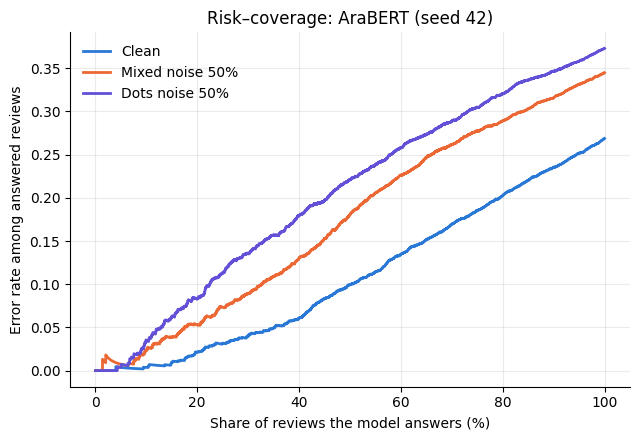

In [39]:
L = np.load(f'{LOGITS_DIR}/AraBERT_standard_s42.npz')
T_c = fit_temperature(L['val'], L['val_labels'])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for key, label, color, ls in [('test_clean', 'Clean', '#2a78d6', '-'),
                              ('mixed_0.5', 'Mixed noise 50%', '#eb6834', '-'),
                              ('dots_0.5', 'Dots noise 50%', '#6250d6', '-')]:
    cov, risk, _ = risk_coverage(get_probs(L, key, 'none', T_c), L['test_labels'])
    ax.plot(cov * 100, risk, color=color, linestyle=ls, linewidth=2, label=label)
ax.set_xlabel('Share of reviews the model answers (%)')
ax.set_ylabel('Error rate among answered reviews')
ax.set_title('Risk–coverage: AraBERT (seed 42)')
ax.grid(alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/risk_coverage_AraBERT_s42.png', dpi=300, bbox_inches='tight')
plt.show()

---
## <font color="#1c5cab">9. Final results</font>

This section brings all the results together into the final tables and the main figure used in the paper, and saves them to Drive (`results/paper_tables/` and `figures/`).

### 9.1 Final tables

| Table | Content |
|---|---|
| **Table 1** | Accuracy of standard and noise-augmented models, on clean text and with 50% noise |
| **Table 2** | Calibration error (ECE) for every model and method |
| **Table 3** | The deployment test: actual error and share accepted, with no fix and with TTS |
| **Table 4** | Text normalization as a defense |

All values are averages ± the variation over three seeds (Table 4: average of the 9 standard models).

In [42]:
TABLE_DIR = f'{RESULTS_DIR}/paper_tables'
os.makedirs(TABLE_DIR, exist_ok=True)

def fmt(g):
    return g['mean'].map('{:.3f}'.format) + ' ± ' + g['std'].map('{:.3f}'.format)

SETS = [('Clean', 'clean', 0.0), ('Mixed 50%', 'mixed', 0.5),
        ('Dots 50%', 'dots', 0.5), ('Typo 50%', 'typo', 0.5)]
MODELS = list(CONFIG['models'])

# Table 1: accuracy, standard vs noise-augmented training
base = all_res[all_res['method'] == 'none']
table1 = pd.concat([fmt(base[(base['type'] == t) & (base['level'] == lv)]
                        .groupby(['model', 'variant'])['accuracy'].agg(['mean', 'std'])).rename(lab)
                    for lab, t, lv in SETS], axis=1)
table1 = table1.reindex(pd.MultiIndex.from_product([MODELS, ['standard', 'noiseaug']]))

# Table 2: calibration error (ECE, 15 bins) by method
std_ = all_res[all_res['variant'] == 'standard']
na_tts = all_res[(all_res['variant'] == 'noiseaug') & (all_res['method'] == 'TTS')].assign(method='noiseaug+TTS')
d2 = pd.concat([std_, na_tts])
METHODS = ['none', 'MC', 'TS', 'TTS', 'noiseaug+TTS']
table2 = pd.concat([fmt(d2[(d2['type'] == t) & (d2['level'] == lv)]
                        .groupby(['model', 'method'])['ece_15'].agg(['mean', 'std'])).rename(lab)
                    for lab, t, lv in SETS], axis=1)
table2 = table2.reindex(pd.MultiIndex.from_product([MODELS, METHODS]))

# Table 3: deployment test (threshold set on clean data for 10% error)
d3 = sel[(sel['variant'] == 'standard') & (sel['method'].isin(['none', 'TTS']))]
cols3 = []
for lab, t, lv in SETS[:3]:
    d = d3[(d3['type'] == t) & (d3['level'] == lv)]
    for col, nm in [('risk_at_tau', 'error'), ('coverage_at_tau', 'accepted')]:
        cols3.append(fmt(d.groupby(['model', 'method'])[col].agg(['mean', 'std'])).rename(f'{lab}: {nm}'))
table3 = pd.concat(cols3, axis=1).reindex(pd.MultiIndex.from_product([MODELS, ['none', 'TTS']]))

# Table 4: normalization baseline (average of 9 standard models, noise at 50%)
norm_order = ['clean'] + CONFIG['noise_types']
table4 = pd.concat([
    norm_res[norm_res['method'] == 'none'].pivot_table(index='type', columns='setup', values='accuracy')
        .add_prefix('accuracy, '),
    norm_res.pivot_table(index='type', columns=['setup', 'method'], values='ece_15')
        .pipe(lambda x: x.set_axis([f'ECE, {s} + {m}' for s, m in x.columns], axis=1))
], axis=1).loc[norm_order].round(3)
table4 = table4[['accuracy, raw', 'accuracy, normalized',
                 'ECE, raw + none', 'ECE, normalized + none',
                 'ECE, raw + TTS', 'ECE, normalized + TTS']]

for i, (title, tab) in enumerate([
        ('Table 1. Accuracy (mean ± std over 3 seeds)', table1),
        ('Table 2. Calibration error, ECE 15 bins (mean ± std over 3 seeds)', table2),
        ('Table 3. Threshold set on clean data for 10% error, applied to noisy data', table3),
        ('Table 4. Text normalization as a defense (average of 9 standard models)', table4)], 1):
    print(f'\n{title}')
    display(tab)
    tab.to_csv(f'{TABLE_DIR}/table{i}.csv')
print('\nTables saved to', TABLE_DIR)


Table 1. Accuracy (mean ± std over 3 seeds)


Clean      Mixed 50%       Dots 50%       Typo 50%
AraBERT   standard  0.730 ± 0.003  0.654 ± 0.003  0.620 ± 0.006  0.639 ± 0.005
          noiseaug  0.725 ± 0.004  0.693 ± 0.003  0.677 ± 0.006  0.672 ± 0.003
MARBERT   standard  0.723 ± 0.006  0.653 ± 0.004  0.612 ± 0.007  0.626 ± 0.003
          noiseaug  0.724 ± 0.002  0.687 ± 0.002  0.668 ± 0.003  0.660 ± 0.006
CAMeLBERT standard  0.714 ± 0.007  0.635 ± 0.002  0.586 ± 0.006  0.611 ± 0.009
          noiseaug  0.712 ± 0.002  0.679 ± 0.005  0.660 ± 0.005  0.656 ± 0.007


Table 2. Calibration error, ECE 15 bins (mean ± std over 3 seeds)


Clean      Mixed 50%       Dots 50%  \
AraBERT   none          0.080 ± 0.025  0.112 ± 0.022  0.132 ± 0.024   
          MC            0.059 ± 0.023  0.079 ± 0.017  0.098 ± 0.016   
          TS            0.022 ± 0.009  0.045 ± 0.002  0.066 ± 0.006   
          TTS           0.023 ± 0.010  0.025 ± 0.001  0.026 ± 0.005   
          noiseaug+TTS  0.029 ± 0.010  0.025 ± 0.005  0.027 ± 0.006   
MARBERT   none          0.055 ± 0.027  0.078 ± 0.040  0.095 ± 0.051   
          MC            0.033 ± 0.018  0.039 ± 0.033  0.057 ± 0.036   
          TS            0.030 ± 0.008  0.046 ± 0.019  0.064 ± 0.028   
          TTS           0.031 ± 0.009  0.030 ± 0.014  0.041 ± 0.019   
          noiseaug+TTS  0.036 ± 0.013  0.035 ± 0.017  0.046 ± 0.017   
CAMeLBERT none          0.074 ± 0.044  0.119 ± 0.054  0.148 ± 0.053   
          MC            0.051 ± 0.039  0.088 ± 0.047  0.122 ± 0.047   
          TS            0.023 ± 0.011  0.058 ± 0.019  0.086 ± 0.018   
          TTS           0.023 ± 0.012  0.040 ± 0.014  0.053 ± 0.010   
          noiseaug+TTS  0.024 ± 0.007  0.027 ± 0.010  0.035 ± 0.016   

                             Typo 50%  
AraBERT   none          0.116 ± 0.024  
          MC            0.084 ± 0.017  
          TS            0.051 ± 0.004  
          TTS           0.023 ± 0.001  
          noiseaug+TTS  0.029 ± 0.002  
MARBERT   none          0.080 ± 0.043  
          MC            0.040 ± 0.031  
          TS            0.049 ± 0.023  
          TTS           0.031 ± 0.009  
          noiseaug+TTS  0.033 ± 0.011  
CAMeLBERT none          0.118 ± 0.058  
          MC            0.093 ± 0.049  
          TS            0.056 ± 0.024  
          TTS           0.031 ± 0.008  
          noiseaug+TTS  0.031 ± 0.012


Table 3. Threshold set on clean data for 10% error, applied to noisy data


Clean: error Clean: accepted Mixed 50%: error  \
AraBERT   none  0.104 ± 0.000   0.516 ± 0.004    0.151 ± 0.004   
          TTS   0.104 ± 0.002   0.516 ± 0.008    0.124 ± 0.002   
MARBERT   none  0.107 ± 0.007   0.505 ± 0.023    0.143 ± 0.015   
          TTS   0.108 ± 0.008   0.509 ± 0.023    0.122 ± 0.015   
CAMeLBERT none  0.099 ± 0.004   0.478 ± 0.014    0.167 ± 0.022   
          TTS   0.100 ± 0.005   0.482 ± 0.018    0.143 ± 0.026   

               Mixed 50%: accepted Dots 50%: error Dots 50%: accepted  
AraBERT   none       0.421 ± 0.016   0.195 ± 0.005      0.398 ± 0.023  
          TTS        0.357 ± 0.031   0.153 ± 0.007      0.311 ± 0.043  
MARBERT   none       0.412 ± 0.040   0.163 ± 0.026      0.352 ± 0.051  
          TTS        0.366 ± 0.040   0.127 ± 0.018      0.284 ± 0.043  
CAMeLBERT none       0.421 ± 0.030   0.216 ± 0.021      0.370 ± 0.029  
          TTS        0.370 ± 0.036   0.178 ± 0.042      0.299 ± 0.036


Table 4. Text normalization as a defense (average of 9 standard models)


,"accuracy, normalized","accuracy, raw","ECE, normalized + TTS","ECE, normalized + none","ECE, raw + TTS","ECE, raw + none"
type,,,,,,
clean,0.719,0.722,0.026,0.070,0.026,0.070
hamza,0.719,0.722,0.026,0.070,0.026,0.070
taa,0.719,0.720,0.026,0.070,0.024,0.069
ya,0.719,0.721,0.026,0.070,0.027,0.071
dots,0.606,0.606,0.036,0.119,0.040,0.125
repeat,0.718,0.658,0.026,0.069,0.054,0.116
typo,0.621,0.625,0.027,0.103,0.028,0.105
mixed,0.667,0.647,0.025,0.086,0.031,0.103



Tables saved to /content/drive/MyDrive/arabic_sa_calibration/results/paper_tables


### 9.2 Summary figure (all 9 standard models together)

The main figure of the project. Each panel is one type of noise; each line is a method, averaged over all three models and seeds.

**How to read it:** without a fix (blue) the error rises with noise; MC dropout (yellow) helps a little; TS (orange) is good on clean text but rises with noise; **TTS (green) and noise-augmented training + TTS (purple) stay low and flat at every noise level.**

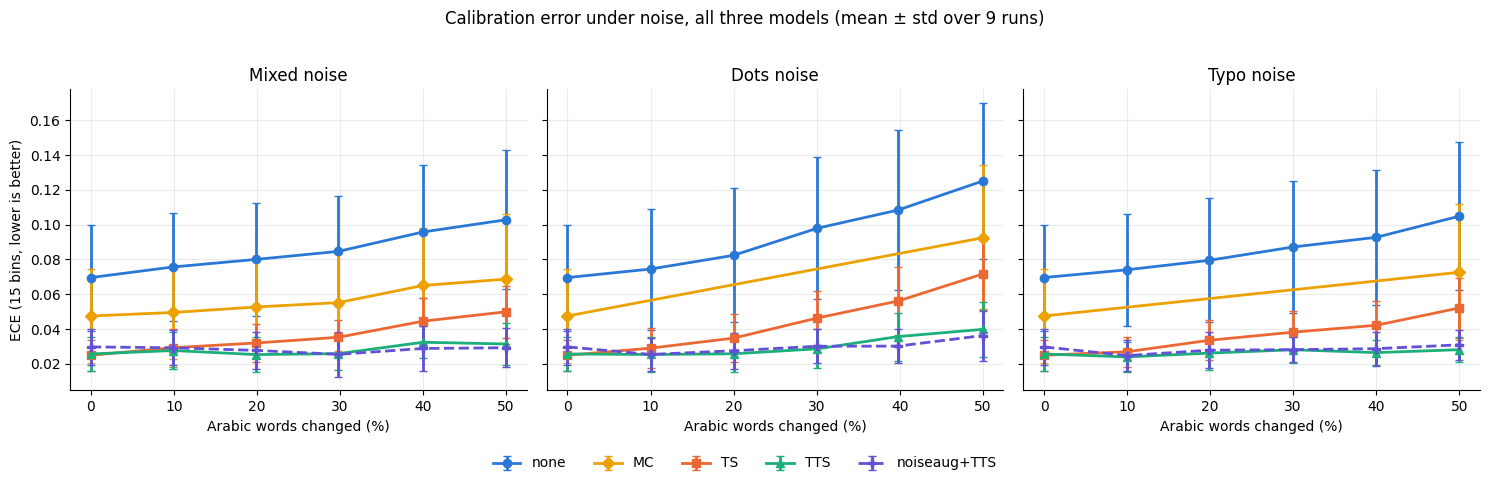

In [43]:
import matplotlib.pyplot as plt

M_COLORS  = {'none': '#2a78d6', 'MC': '#eda100', 'TS': '#eb6834', 'TTS': '#1baf7a', 'noiseaug+TTS': '#6250d6'}
M_MARKERS = {'none': 'o', 'MC': 'D', 'TS': 's', 'TTS': '^', 'noiseaug+TTS': 'P'}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, ntype in zip(axes, ['mixed', 'dots', 'typo']):
    d = d2[d2['type'].isin(['clean', ntype])]
    for method in METHODS:
        g = d[d['method'] == method].groupby('words_changed')['ece_15'].agg(['mean', 'std']).reset_index()
        ax.errorbar(g['words_changed'] * 100, g['mean'], yerr=g['std'], color=M_COLORS[method],
                    marker=M_MARKERS[method], markersize=6, linewidth=2, capsize=3,
                    linestyle='--' if method == 'noiseaug+TTS' else '-', label=method)
    ax.set_title(f'{ntype.capitalize()} noise')
    ax.set_xlabel('Arabic words changed (%)')
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('ECE (15 bins, lower is better)')
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Calibration error under noise, all three models (mean ± std over 9 runs)', y=1.02)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/summary_ece_all_models.png', dpi=300, bbox_inches='tight')
plt.show()

### 9.3 List of all saved results

Lists every figure, result file and table saved in Google Drive, so they are easy to find when writing the paper.

In [44]:
print('Figures:')
for f in sorted(os.listdir(FIGURES_DIR)):
    print('  ', f)
print('\nResult files:')
for f in sorted(os.listdir(RESULTS_DIR)):
    if os.path.isfile(f'{RESULTS_DIR}/{f}'):
        print('  ', f)
print('\nPaper tables:')
for f in sorted(os.listdir(TABLE_DIR)):
    print('  ', f)

Figures:
   ece_methods_mixed.png
   noise_curves_AraBERT_s42.png
   noiseaug_vs_standard.png
   reliability_AraBERT_s42.png
   risk_coverage_AraBERT_s42.png
   selective_threshold_transfer.png
   summary_ece_all_models.png

Result files:
   all_results.csv
   eval_AraBERT_standard_s42.csv
   noise_realized_rates.csv
   noise_vs_normalization.csv
   normalization_results.csv
   selective_results.csv
   versions.json

Paper tables:
   table1.csv
   table2.csv
   table3.csv
   table4.csv


---
## <font color="#1c5cab">10. Summary and conclusions</font>

**What we did.** We fine-tuned three Arabic language models (AraBERT, MARBERT, CAMeLBERT) to classify reviews as positive, negative or mixed, then tested them on reviews with realistic Arabic spelling mistakes. We measured not only how often the models are right, but whether their confidence is honest, and we compared five ways of improving it.

**What we found.**
1. **All three models are overconfident**, even on clean text, and spelling mistakes make it worse. With 50% dot-confusion noise, AraBERT's calibration error grows from 0.080 to 0.132.
2. **Not all mistakes are equal.** Hamza, ة/ه and ى/ي mistakes barely affect the models. Dot confusion and keyboard typos are the most damaging, and **text normalization cannot fix them**.
3. **Standard temperature scaling works on clean text but fails under noise.**
4. **Transferable temperature scaling (TTS) keeps confidence honest at every noise level** (AraBERT: 0.023 on clean text, 0.026 with 50% dot noise), for all three models. This method had only been tested on English before.
5. **MC dropout helps only a little**, at 10 times the computing cost.
6. **Noise-augmented training improves accuracy on messy text by about 4 points**, but still needs TTS to keep confidence honest.
7. **In a realistic deployment test**, an error target of 10% quietly grows to 15–22% on messy reviews without a fix; TTS cuts this extra error roughly in half.

**Recommendation for practice.** Use noise-augmented training if retraining is possible, normalize the text, and apply TTS. If retraining is not possible, TTS alone already keeps confidence much more honest.

**Limitations.**
- The spelling mistakes are generated by rules, not collected from real users.
- TTS needs a batch of incoming reviews to measure how messy they are; it cannot adjust for a single review.
- One dataset (reviews) and one model size (BERT-base) were studied.

**Future work.** Test with real noisy reviews and social-media text, larger and newer models, and noise-aware methods that work on a single review.